# 15 — Multimodal MMLongBench-Doc: page images versus extracted text

## Objective

Notebook 14 found that, with text input, gpt-4o-mini answers 7 of 40 answerable questions correctly with the BM25 pages (0.175) and 9 of 40 with the annotated evidence pages (0.225). Most remaining errors involve charts and figures. This notebook tests whether the **representation of the evidence** is the cause.

**Research question.** With the same model, the same questions and the **same evidence pages**, does sending **rendered page images** instead of extracted/OCR text improve question answering?

**Hypotheses to test (not conclusions):**

- **H1** — On the BM25-retrieved pages, image input scores higher than text input.
- **H2** — The image-over-text gain is larger on chart/figure questions than on the other answerable questions.
- **H3** — On the oracle pages, image input scores higher than text input.

**Conditions** (README §6). A and C are frozen results from Notebook 14; B and D are new here:

| | BM25-retrieved pages (top 5) | Oracle pages (evidence, padded to 5) |
|---|---|---|
| **Extracted text** (native + OCR) | **A** — 0.175 (Notebook 14, Step 9) | **C** — 0.225 (Notebook 14, Step 13) |
| **Rendered page images** | **B** — this notebook | **D** — this notebook |

## Scope and honesty rules

- Conditions A and C are **not re-run**. Their predictions are read from the saved run `20261119T220858Z_a351a532`, re-scored, and checked against the saved scores. B and D use **exactly the same page lists, in the same order**, taken from that run.
- Paid API calls are **opt-in**. `VISUALDOC_VISION_MODE` defaults to `off`. This variable is separate from Notebook 14's `VISUALDOC_GENERATION_MODE`, so a `full` setting left over for Notebook 14 cannot start paid image requests here.
- A failed API call is an infrastructure failure, not a wrong answer. If a condition is incomplete, it reports **no** metric.
- When a comparison is not perfectly controlled, the difference is stated (Concept section, Step 8 and Limitations), not hidden.
- 57 questions in 6 documents form a **development subset**. Every subgroup result is exploratory.

**How to run.** Execute from top to bottom with the `visualdoc-venv` kernel. To call the API, set `VISUALDOC_VISION_MODE` to `smoke`, `pilot` or `full` (shell or `.env`) and re-execute. Always run in this order: `smoke` → `pilot` → `full`.

## Concept

### Pipeline: only the evidence representation changes

```text
                          ┌─ A/C: page text (native + OCR, ≤3,500 chars/page) ─┐
question ─► page list ────┤                                                     ├─► gpt-4o-mini ─► {answer, cited_pages} ─► same scorer
(frozen from NB14)        └─ B/D: page images (PyMuPDF render, PNG)  ───────────┘
```

**Held constant between text and image:** questions and question ids, reference answers, the page list and its order, the `[Page N]` labels (1-based physical page numbers), the model snapshot, temperature 0, `max_completion_tokens`, JSON output mode, the answer parser and the scoring rules.

**What differs, besides the representation itself** (stated now so that it is not hidden later):

1. **System-prompt wording.** "page excerpts" becomes "page images" in 5 of the 10 lines. Nothing else changes (Step 7 shows the diff).
2. **Resolution is limited by the token budget, not chosen freely.** gpt-4o-mini counts every 512 px image tile as about 5,667 input tokens (Step 8). At the API's default high-detail size (shortest side 768 px), 5 pages already take more than ~127k tokens, beyond the 128k context window. So pages are rendered into a 512 × 1024 px box (≈ 60 dpi for a letter page). Small text can be lost, and Steps 5–6 measure how much.
3. **Context limit on large oracle sets.** Two oracle questions have 10 and 13 evidence pages. At this resolution their requests may not fit the context window. They are then **skipped by protocol before any call**, the oracle comparison uses the remaining questions, and the text side is restricted to the same questions.
4. **Text truncation.** Condition A/C truncated each page's text at 3,500 characters; images are never truncated.

### Image token cost (why resolution and page count interact)

For high-detail images on tile-based models, the documented procedure is: fit the image within 2048 × 2048, scale the shortest side to 768 px, then count 512 px tiles. Cost:

$$\text{tokens}(\text{image}) = b + t \cdot \left\lceil \tfrac{w'}{512} \right\rceil \left\lceil \tfrac{h'}{512} \right\rceil$$

with $b = 2{,}833$ and $t = 5{,}667$ for gpt-4o-mini (community-reported values; gpt-4o uses 85 and 170). Public sources **disagree** on whether an image smaller than 768 px is scaled *up* to 768 px. If it is, rendering smaller saves nothing. The smoke test (Step 10) measures `usage.prompt_tokens` on one synthetic page and decides which rule applies **before** any benchmark question is sent.

### Paired analysis

Each question is answered under both conditions of a comparison, so it is its own control. We report transitions (fixed / broken / both right / both wrong) and the exact McNemar test on the discordant pairs:

$$p = \min\!\left(1,\; 2 \sum_{i=0}^{\min(f, r)} \binom{f + r}{i} 2^{-(f+r)}\right), \quad f = \text{fixed},\; r = \text{broken}.$$

McNemar assumes independent questions. Here the questions are **clustered in 6 documents** (same layout, same rendering quality), so the p-value is optimistic. Per-document tables are shown so the reader can see whether one document drives a difference.

## Setup

Self-contained: every operation is rebuilt visibly in this notebook. Nothing is imported from `src/visualdoc/`, and no variable from another notebook is used. The only inputs from Notebook 14 are its **saved files** in the frozen run folder, which are read and verified in Step 1.

In [1]:
from collections import Counter, deque
from datetime import datetime, timezone
from math import ceil, comb, isclose, log
from pathlib import Path
import ast
import base64
import difflib
import hashlib
import json
import os
import platform
import re
import sys
import tempfile
import textwrap
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
from huggingface_hub import hf_hub_download
from IPython.display import Markdown, display

try:
    import tiktoken
except ImportError:
    tiktoken = None  # text-token estimates then fall back to characters / 4

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
MMLONG_DIR = PROJECT_ROOT / "data" / "external" / "mmlongbench_doc"
TEXT_RUNS_DIR = PROJECT_ROOT / "experiments" / "runs" / "mmlongbench_doc"  # Notebook 14 runs (read only)
RUNS_DIR = PROJECT_ROOT / "experiments" / "runs" / "mmlongbench_doc_multimodal"  # this notebook's runs
CACHE_DIR = PROJECT_ROOT / "data" / "cache" / "mmlongbench_doc"  # git-ignored, regenerable
TESSDATA_DIR = PROJECT_ROOT / "resources" / "tessdata"

print("Python:", sys.version.split()[0], "| PyMuPDF:", pymupdf.VersionBind, "| pandas:", pd.__version__, "| numpy:", np.__version__,
      "| tiktoken:", getattr(tiktoken, "__version__", None))
print("Project root folder:", PROJECT_ROOT.name)

Python: 3.12.6 | PyMuPDF: 2.1 | pandas: 3.1.1 | numpy: 2.3.5 | tiktoken: 0.14.0
Project root folder: Multimodal-Document-Intelligence


## Run settings

All settings live in one dictionary, saved with every run. They fall into three groups:

- **Copied from the frozen baseline run** (not re-chosen): dataset revision, document subset, OCR and BM25 parameters, `generation_top_k`, temperature, output-token limit, pilot questions.
- **Model snapshot.** We request `gpt-4o-mini-2024-07-18`, the exact snapshot that served every baseline request (checked in Step 1). Notebook 14 requested the alias `gpt-4o-mini`. Pinning the dated snapshot prevents a silent model update from confounding the comparison.
- **Image and cost settings.** The render box, `detail`, token constants, list prices and a cost cap. The token constants are measured by the smoke test before they are trusted. The prices are list prices assumed for gpt-4o-mini, so check them on OpenAI's pricing page. `max_estimated_live_cost_usd` blocks any batch whose estimated cost for uncached requests is higher.
- `request_timeout_s` is 120 s instead of Notebook 14's 60 s, because image requests take longer. This affects infrastructure only, not the experimental conditions.

In [2]:
try:
    from dotenv import load_dotenv

    load_dotenv(PROJECT_ROOT / ".env")
except ImportError:
    pass  # python-dotenv is optional; plain environment variables still work

BASELINE_RUN_ID = "20261119T220858Z_a351a532"  # Notebook 14: full text run + oracle-page condition
BASELINE_DIR = TEXT_RUNS_DIR / BASELINE_RUN_ID
baseline_settings = json.loads((BASELINE_DIR / "settings.json").read_text())

COPIED_FROM_BASELINE = [
    "dataset_repo", "dataset_revision", "subset_documents", "ocr_min_native_words", "ocr_dpi", "bm25_k1", "bm25_b",
    "generation_top_k", "max_chars_per_page", "temperature", "max_output_tokens", "pilot_qids", "scoring",
]
SETTINGS = {
    "baseline_run_id": BASELINE_RUN_ID,
    **{key: baseline_settings[key] for key in COPIED_FROM_BASELINE},
    # Model: the snapshot that served the baseline (verified in Step 1).
    "model_provider": "openai",
    "model_name": os.getenv("VISUALDOC_VISION_MODEL", "gpt-4o-mini-2024-07-18"),
    "prompt_version": "mmlb-image-v1",
    # Page images.
    "image_format": "png",
    "image_detail": "high",
    "render_max_short_side_px": 512,
    "render_max_long_side_px": 1024,
    # Cost model for gpt-4o-mini, high detail (community-reported; measured by the smoke test in Step 10).
    "image_base_tokens": 2833,
    "image_tile_tokens": 5667,
    "context_window_tokens": 128_000,
    "price_usd_per_1m_input_tokens": 0.15,  # assumed list price, verify before relying on costs
    "price_usd_per_1m_output_tokens": 0.60,
    "max_estimated_live_cost_usd": 2.50,  # a batch whose uncached requests are estimated above this is refused
    "default_tokens_per_minute": 150_000,  # pacing budget if the smoke test cannot read the account's limit
    # Execution. "off" makes no call; "smoke" one synthetic test call; "pilot" smoke + the 5 pilot questions;
    # "full" smoke + all 57 questions (condition B) and the oracle questions (condition D).
    "vision_mode": os.getenv("VISUALDOC_VISION_MODE", "off"),
    "reuse_cached_responses": True,
    "max_attempts": 3,
    "request_timeout_s": 120,
}
assert SETTINGS["vision_mode"] in {"off", "smoke", "pilot", "full"}, "VISUALDOC_VISION_MODE must be off, smoke, pilot or full"
assert SETTINGS["image_detail"] in {"high", "low"}
{key: value for key, value in SETTINGS.items() if key not in ("subset_documents", "scoring")}

{'baseline_run_id': '20261119T220858Z_a351a532',
 'dataset_repo': 'yubo2333/MMLongBench-Doc',
 'dataset_revision': '2ff6aa9237fc777b6627dc57a486e9225ac5fb86',
 'ocr_min_native_words': 30,
 'ocr_dpi': 150,
 'bm25_k1': 1.5,
 'bm25_b': 0.75,
 'generation_top_k': 5,
 'max_chars_per_page': 3500,
 'temperature': 0.0,
 'max_output_tokens': 400,
 'pilot_qids': ['mmlb-0036',
  'mmlb-0355',
  'mmlb-0731',
  'mmlb-0734',
  'mmlb-0736'],
 'model_provider': 'openai',
 'model_name': 'gpt-4o-mini-2024-07-18',
 'prompt_version': 'mmlb-image-v1',
 'image_format': 'png',
 'image_detail': 'high',
 'render_max_short_side_px': 512,
 'render_max_long_side_px': 1024,
 'image_base_tokens': 2833,
 'image_tile_tokens': 5667,
 'context_window_tokens': 128000,
 'price_usd_per_1m_input_tokens': 0.15,
 'price_usd_per_1m_output_tokens': 0.6,
 'max_estimated_live_cost_usd': 2.5,
 'default_tokens_per_minute': 150000,
 'vision_mode': 'off',
 'reuse_cached_responses': True,
 'max_attempts': 3,
 'request_timeout_s': 120}

## Step 1 — Load and verify the frozen text baseline

**What:** read the benchmark questions from the pinned dataset revision, and the text predictions (conditions A and C) from the saved run.

**Why verify instead of trusting the files:** every paired comparison below assumes four things. The question ids match, the reference answers match, the text predictions all came from successful calls, and one model snapshot produced them. A mismatch in any of them would make "image minus text" meaningless, so each one is asserted.

In [3]:
questions_path = hf_hub_download(
    repo_id=SETTINGS["dataset_repo"],
    repo_type="dataset",
    revision=SETTINGS["dataset_revision"],
    filename="data/train-00000-of-00001.parquet",
    local_dir=MMLONG_DIR,
)
raw = pd.read_parquet(questions_path)
raw.insert(0, "qid", [f"mmlb-{index:04d}" for index in raw.index])  # row position = id, stable for the pinned revision

subset = raw[raw["doc_id"].isin(SETTINGS["subset_documents"])].reset_index(drop=True)
subset["evidence_pages"] = subset["evidence_pages"].map(ast.literal_eval)  # stored as strings such as '[5]'
subset["evidence_sources"] = subset["evidence_sources"].map(ast.literal_eval)
subset["answerable"] = subset["answer"] != "Not answerable"
VISUAL_SOURCES = {"Chart", "Figure"}
subset["evidence_group"] = np.where(
    ~subset["answerable"],
    "unanswerable",
    np.where(subset["evidence_sources"].map(lambda sources: bool(VISUAL_SOURCES & set(sources))), "chart or figure", "text, layout or table only"),
)


def read_jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]


text_retrieved_records = read_jsonl(BASELINE_DIR / "predictions.jsonl")  # condition A
text_oracle_records = read_jsonl(BASELINE_DIR / "oracle_predictions.jsonl")  # condition C
saved_scored = pd.read_csv(BASELINE_DIR / "scored_predictions.csv")
saved_oracle_paired = pd.read_csv(BASELINE_DIR / "oracle_paired.csv")
saved_ranking = dict(zip(saved_scored["qid"], saved_scored["ranking"].map(ast.literal_eval)))  # full BM25 ranking per question

baseline_overview = pd.DataFrame(
    [
        {
            "condition": name,
            "file": file,
            "questions": len(records),
            "statuses": dict(Counter(r["status"] for r in records)),
            "served model": ", ".join(sorted({r["served_model"] for r in records})),
            "prompt tokens": sum(r["prompt_tokens"] for r in records),
        }
        for name, file, records in [
            ("A. retrieved text", "predictions.jsonl", text_retrieved_records),
            ("C. oracle text", "oracle_predictions.jsonl", text_oracle_records),
        ]
    ]
)
print(f"Subset: {len(subset)} questions ({int(subset['answerable'].sum())} answerable) in {subset['doc_id'].nunique()} documents")
display(baseline_overview)
display(subset.groupby("evidence_group").size().rename("questions").to_frame())

Subset: 57 questions (40 answerable) in 6 documents


,condition,file,questions,statuses,served model,prompt tokens
0,A. retrieved text,predictions.jsonl,57,{'ok': 57},gpt-4o-mini-2024-07-18,107988
1,C. oracle text,oracle_predictions.jsonl,40,{'ok': 40},gpt-4o-mini-2024-07-18,73170


,questions
evidence_group,
chart or figure,32
"text, layout or table only",8
unanswerable,17


In [4]:
reference = subset.set_index("qid")

# 1. Same question ids, in the same order, as the baseline run.
assert subset["qid"].tolist() == baseline_settings["subset_qids"]
assert [record["qid"] for record in text_retrieved_records] == subset["qid"].tolist()

# 2. Same reference answers: the saved table agrees with the pinned parquet (compared as strings).
saved_answers = saved_scored.set_index("qid")["answer"].astype(str)
assert (saved_answers == reference.loc[saved_answers.index, "answer"].astype(str)).all()

# 3. Every baseline request succeeded: no failed call is hiding as a wrong answer.
assert all(record["status"] == "ok" for record in text_retrieved_records + text_oracle_records)

# 4. One snapshot served the whole baseline, and it is the snapshot this notebook requests.
baseline_served = {record["served_model"] for record in text_retrieved_records + text_oracle_records}
assert baseline_served == {SETTINGS["model_name"]}, f"baseline served {baseline_served}, this notebook requests {SETTINGS['model_name']!r}"

# 5. The oracle population is exactly the answerable questions with evidence pages.
oracle_qids = [record["qid"] for record in text_oracle_records]
assert set(oracle_qids) == set(subset.loc[subset["answerable"] & subset["evidence_pages"].map(len).gt(0), "qid"])

print(f"Baseline checks passed: {len(subset)} question ids and reference answers match the pinned dataset; "
      f"{len(text_retrieved_records)} + {len(text_oracle_records)} text requests all succeeded; served model {baseline_served.pop()}.")

Baseline checks passed: 57 question ids and reference answers match the pinned dataset; 57 + 40 text requests all succeeded; served model gpt-4o-mini-2024-07-18.


## Step 2 — The same scoring rules, re-checked

The scorer is copied **verbatim** from Notebook 14 Step 8, a local re-implementation of the rule-based stage of MMLongBench-Doc `eval/eval_score.py` @ `d73f0dc`. See Notebook 14 for the rule table, the documented deviations and the kept `rstrip` quirk.

Two checks show it is the same scorer: (1) the hand-traced rule cases from Notebook 14 pass; (2) **re-scoring the saved text predictions reproduces the saved per-question scores exactly**, and from them the 0.175 and 0.225 answerable accuracies. Any difference between text and image results below can therefore not come from a scoring change.

In [5]:
def levenshtein_distance(s1, s2):
    if len(s1) > len(s2):
        s1, s2 = s2, s1
    distances = range(len(s1) + 1)
    for i2, c2 in enumerate(s2):
        new_distances = [i2 + 1]
        for i1, c1 in enumerate(s1):
            if c1 == c2:
                new_distances.append(distances[i1])
            else:
                new_distances.append(1 + min(distances[i1], distances[i1 + 1], new_distances[-1]))
        distances = new_distances
    return distances[-1]


def anls_compute(groundtruth, prediction, threshold=0.5):
    length = max(len(groundtruth.upper()), len(prediction.upper()))
    value = 0.0 if length == 0 else levenshtein_distance(groundtruth, prediction) / length
    anls = 1.0 - value
    return 0.0 if anls <= threshold else anls


def is_float_equal(reference, prediction, include_percentage=False, is_close=False):
    def get_precision(value):
        text = str(value)
        return len(text.split(".")[-1]) if "." in text else 3

    reference = float(str(reference).strip().rstrip("%").strip())
    try:
        prediction = float(str(prediction).strip().rstrip("%").strip())
    except (TypeError, ValueError):
        return False
    candidates = [reference / 100, reference, reference * 100] if include_percentage else [reference]
    for item in candidates:
        if is_close and isclose(item, prediction, rel_tol=0.01):
            return True
        precision = max(min(get_precision(prediction), get_precision(item)), 2)
        if round(prediction, precision) == round(item, precision):
            return True
    return False


def get_clean_string(s):
    s = str(s).lower().strip()
    # Official quirk: the code calls s.rstrip("mile") etc. without assigning the result,
    # so unit suffixes are NOT removed. Kept to reproduce official scores.
    s = re.sub(r"\s*\([^)]*\)", "", s).strip()  # remove parenthesised text
    s = re.sub(r"^['\"]|['\"]$", "", s).strip()  # remove surrounding quotes
    s = s.strip().lstrip("$").strip()
    s = s.strip().rstrip("%").strip()
    return s


EXACT_MATCH_PATTERNS = [
    r"\b\d+(-\d+|\s\d+)?\b",  # phone-like numbers
    r"\b\d{4}[-\s]\d{2}[-\s]\d{2}\b",  # YYYY-MM-DD
    r"\b\d{4}[-\s]\d{2}\b",  # YYYY-MM
    r"[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}",  # e-mail address
]


def is_exact_match(s):
    return (
        "https://" in s
        or s.endswith(".py")
        or s.endswith("ipynb")
        or s.startswith("page")
        or "a.m." in s
        or "p.m." in s
        or any(re.fullmatch(pattern, s) for pattern in EXACT_MATCH_PATTERNS)
    )


def isfloat(value):
    try:
        float(value)
        return True
    except (TypeError, ValueError):
        return False


def as_list(value):
    if isinstance(value, str) and value.startswith("["):
        try:
            value = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            pass  # deviation: the official eval() would raise here
    return value if isinstance(value, list) else [value]


def eval_score(gt, pred, answer_type):
    if answer_type == "Int":
        try:
            gt, pred = int(gt), int(float(pred))
        except Exception:  # the official code uses a bare except
            pred = ""
        score = gt == pred
    elif answer_type == "Float":
        try:
            gt = float(get_clean_string(str(gt)))
            pred = float(get_clean_string(str(pred)))
        except Exception:
            pred = ""
        score = is_float_equal(gt, pred, include_percentage=True, is_close=True)
    elif answer_type in ("Str", "None"):
        gt, pred = get_clean_string(gt), get_clean_string(pred)
        score = gt == pred if is_exact_match(gt) else anls_compute(gt, pred)
    else:  # List
        gt, pred = as_list(gt), as_list(pred)
        if len(gt) != len(pred):
            score = 0.0
        else:
            gt = sorted(get_clean_string(item) for item in gt)
            pred = sorted(get_clean_string(item) for item in pred)
            if isfloat(gt[0]) or is_exact_match(gt[0]):
                score = "-".join(gt) == "-".join(pred)
            else:
                score = min(anls_compute(g, p) for g, p in zip(gt, pred))
    return float(score)


def accuracy_and_f1(scored):
    """scored: DataFrame with columns answer, pred, score. Official MMLongBench-Doc definitions."""
    if scored.empty:
        return float("nan"), float("nan")
    accuracy = scored["score"].mean()
    answerable = scored["answer"] != "Not answerable"
    predicted_answer = scored["pred"] != "Not answerable"
    if answerable.sum() == 0 or predicted_answer.sum() == 0:
        return accuracy, 0.0  # the official code catches this ZeroDivisionError and returns F1 = 0
    recall = scored.loc[answerable, "score"].sum() / answerable.sum()
    precision = scored.loc[answerable, "score"].sum() / predicted_answer.sum()
    f1 = 2 * recall * precision / (recall + precision) if recall + precision > 0 else 0.0
    return accuracy, f1

In [6]:
SCORING_CASES = [  # reference, prediction, format, expected (hand-traced in Notebook 14, Step 8)
    ("Less well-off", "less well off", "Str", 1 - 1 / 13),
    ("Pew Research Center", "Pew Research Centre", "Str", 1 - 2 / 19),
    ("Latinos", "Asian Americans", "Str", 0.0),
    ("Not answerable", "Not answerable", "None", 1.0),
    ("Not answerable", "The report does not say", "None", 0.0),
    ("12", "12.0", "Int", 1.0),
    ("12", "twelve", "Int", 0.0),
    ("18.29%", "18.3", "Float", 1.0),
    ("0.1", "10%", "Float", 1.0),
    ("51%", "49", "Float", 0.0),
    ("['Circle', 'Rectangle']", "['rectangle', 'circle']", "List", 1.0),
    ("['White', '10%']", "['White']", "List", 0.0),
    ("['2014', '2016']", "['2016', '2014']", "List", 1.0),
    ("https://www.example.com", "www.example.com", "Str", 0.0),
    ("2016-06", "2016-06", "Str", 1.0),
    ("$1,200 (approx.)", "1,200", "Str", 1.0),
    ("5 miles", "5", "Str", 0.0),
]
assert all(isclose(eval_score(r, p, f), expected, abs_tol=1e-9) for r, p, f, expected in SCORING_CASES)


def rescore(records):
    """Score saved prediction records against the pinned reference answers."""
    return pd.Series(
        {r["qid"]: eval_score(reference.loc[r["qid"], "answer"], r["pred"], reference.loc[r["qid"], "answer_format"]) for r in records},
        name="score",
    )


rescored_a = rescore(text_retrieved_records)
rescored_c = rescore(text_oracle_records)
saved_a = saved_scored.set_index("qid")["score"]
saved_c = saved_oracle_paired.set_index("qid")["oracle_score"]
assert np.allclose(rescored_a.loc[saved_a.index], saved_a, atol=1e-12), "condition A scores differ from the saved run"
assert np.allclose(rescored_c.loc[saved_c.index], saved_c, atol=1e-12), "condition C scores differ from the saved run"

answerable_qids = subset.loc[subset["answerable"], "qid"].tolist()
check = pd.DataFrame(
    {
        "re-scored here": [rescored_a.loc[answerable_qids].mean(), rescored_c.mean()],
        "Notebook 14 (saved)": [saved_scored.loc[saved_scored["answerable"], "score"].mean(), saved_c.mean()],
    },
    index=["A. retrieved text — answerable accuracy", "C. oracle text — answerable accuracy"],
)
print(f"{len(SCORING_CASES)} rule checks passed; every saved per-question score is reproduced exactly.")
check.round(3)

17 rule checks passed; every saved per-question score is reproduced exactly.


,re-scored here,Notebook 14 (saved)
A. retrieved text — answerable accuracy,0.175,0.175
C. oracle text — answerable accuracy,0.225,0.225


## Step 3 — The page lists: frozen, then independently rebuilt

**What:** conditions B and D must receive **exactly** the pages that A and C received, in the same order. The authoritative lists are the `supplied_pages` recorded in the baseline predictions, which are the pages the text model actually saw.

**Why rebuild them as well?** Copying a file proves nothing about whether it is correct. So the notebook recomputes the whole selection from the PDFs: native text + OCR fallback with the same settings, BM25 with the same parameters, and the oracle padding rule. The recomputed lists must equal the saved ones. This also gives us each page's extracted text, which the error analysis needs ("was the answer present in the text the model received?").

**Cost:** OCR of the ~120 image-only pages takes about a minute. It is local and free.

In [7]:
assert (TESSDATA_DIR / "eng.traineddata").is_file(), "OCR model missing: resources/tessdata/eng.traineddata"

pdf_paths = {
    doc_id: Path(
        hf_hub_download(
            repo_id=SETTINGS["dataset_repo"], repo_type="dataset", revision=SETTINGS["dataset_revision"],
            filename=f"documents/{doc_id}", local_dir=MMLONG_DIR,
        )
    )
    for doc_id in SETTINGS["subset_documents"]
}
pdf_sha256 = {doc_id: hashlib.sha256(path.read_bytes()).hexdigest() for doc_id, path in pdf_paths.items()}

# Same extraction as Notebook 14 Step 4: native text, OCR fallback below the word threshold.
page_rows = []
extraction_started = time.perf_counter()
for doc_id, path in pdf_paths.items():
    with pymupdf.open(path) as pdf:
        for index, page in enumerate(pdf):
            native_text = page.get_text("text", sort=True)
            native_words = len(native_text.split())
            ocr_used = native_words < SETTINGS["ocr_min_native_words"]
            if ocr_used:
                ocr_textpage = page.get_textpage_ocr(language="eng", dpi=SETTINGS["ocr_dpi"], full=True, tessdata=str(TESSDATA_DIR))
                text = page.get_text("text", textpage=ocr_textpage, sort=True)
            else:
                text = native_text
            page_rows.append(
                {
                    "doc_id": doc_id,
                    "page": index + 1,  # 1-based physical page number
                    "native_text": native_text,
                    "native_words": native_words,
                    "ocr_used": ocr_used,
                    "text": text,
                    "width_pt": page.rect.width,
                    "height_pt": page.rect.height,
                    "rotation": page.rotation,
                    "cropbox_is_mediabox": page.cropbox == page.mediabox,
                }
            )
pages = pd.DataFrame(page_rows)
page_lookup = pages.set_index(["doc_id", "page"])
print(f"Extracted {len(pages)} pages in {time.perf_counter() - extraction_started:.0f} s; OCR on {int(pages['ocr_used'].sum())} pages.")
pages.groupby("doc_id").agg(
    pages=("page", "size"),
    page_size_pt=("width_pt", lambda w: f"{w.iloc[0]:.0f} × {pages.loc[w.index[0], 'height_pt']:.0f}"),
    pages_ocr=("ocr_used", "sum"),
    rotated_pages=("rotation", lambda r: int((r != 0).sum())),
    cropbox_differs=("cropbox_is_mediabox", lambda same: int((~same).sum())),
)

Image too small to scale!! (2x36 vs min width of 3)
Line cannot be recognized!!


Extracted 195 pages in 74 s; OCR on 120 pages.


,pages,page_size_pt,pages_ocr,rotated_pages,cropbox_differs
doc_id,,,,,
2210.02442v1.pdf,24,612 × 792,0,0,0
PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,26,612 × 792,1,0,0
bdf54dxa.pdf,54,612 × 792,53,0,0
earlybird-110722143746-phpapp02_95.pdf,41,768 × 576,41,0,0
germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,23,768 × 432,23,0,0
watch_d.pdf,27,595 × 842,2,0,0


In [8]:
TOKEN_PATTERN = re.compile(r"[a-z0-9]+")


def tokenize(text):
    return TOKEN_PATTERN.findall(str(text).lower())


def build_bm25_index(page_texts):
    """page_texts: {page_number: text} for one PDF (same as Notebook 14 Step 6)."""
    tokens = {page: tokenize(text) for page, text in page_texts.items()}
    n_pages = len(tokens)
    frequency = Counter(token for page_tokens in tokens.values() for token in set(page_tokens))
    return {
        "term_counts": {page: Counter(page_tokens) for page, page_tokens in tokens.items()},
        "lengths": {page: len(page_tokens) for page, page_tokens in tokens.items()},
        "avgdl": float(np.mean([len(page_tokens) for page_tokens in tokens.values()])),
        "idf": {token: log(1 + (n_pages - n_t + 0.5) / (n_t + 0.5)) for token, n_t in frequency.items()},
    }


def bm25_rank(index, query, k1=SETTINGS["bm25_k1"], b=SETTINGS["bm25_b"]):
    """All pages, best first; ties broken by page number."""
    terms = set(tokenize(query))
    scored = []
    for page, counts in index["term_counts"].items():
        length_factor = k1 * (1 - b + b * index["lengths"][page] / max(index["avgdl"], 1.0))
        score = sum(index["idf"][term] * counts[term] * (k1 + 1) / (counts[term] + length_factor) for term in terms if counts[term])
        scored.append((page, score))
    return [page for page, _ in sorted(scored, key=lambda item: (-item[1], item[0]))]


bm25_indexes = {doc_id: build_bm25_index(dict(zip(group["page"], group["text"]))) for doc_id, group in pages.groupby("doc_id")}
recomputed_ranking = {row.qid: bm25_rank(bm25_indexes[row.doc_id], row.question) for row in subset.itertuples()}

same_full_ranking = sum(recomputed_ranking[qid] == saved_ranking[qid] for qid in subset["qid"])
print(f"Recomputed BM25 ranking identical to the saved ranking (all pages, all positions): {same_full_ranking} of {len(subset)} questions")
assert same_full_ranking == len(subset), "the rebuilt retrieval differs from the baseline: inspect before continuing"

Recomputed BM25 ranking identical to the saved ranking (all pages, all positions): 57 of 57 questions


In [9]:
gen_k = SETTINGS["generation_top_k"]


def oracle_pages(evidence, ranking, k):
    """All evidence pages, padded with the best-ranked non-evidence pages up to k, in ranking order (Notebook 14 Step 13)."""
    evidence = set(evidence)
    padding = [page for page in ranking if page not in evidence][: max(0, k - len(evidence))]
    chosen = evidence | set(padding)
    return [page for page in ranking if page in chosen]


assert oracle_pages([3, 7], [7, 1, 2, 3, 4], 3) == [7, 1, 3]
assert oracle_pages([1, 2, 3, 4], [4, 9, 3, 2, 1], 2) == [4, 3, 2, 1]

# The authoritative page lists: what the text model actually received.
retrieved_pages_saved = {r["qid"]: list(r["supplied_pages"]) for r in text_retrieved_records}
oracle_pages_saved = {r["qid"]: list(r["supplied_pages"]) for r in text_oracle_records}
subset["retrieved_pages"] = subset["qid"].map(retrieved_pages_saved)
subset["oracle_pages"] = subset["qid"].map(lambda qid: oracle_pages_saved.get(qid))  # None outside the oracle population

# Rebuilt independently, they must be identical, element by element and in order.
for row in subset.itertuples():
    assert row.retrieved_pages == recomputed_ranking[row.qid][:gen_k], row.qid
    if row.oracle_pages is not None:
        assert row.oracle_pages == oracle_pages(row.evidence_pages, recomputed_ranking[row.qid], gen_k), row.qid
        assert set(row.evidence_pages) <= set(row.oracle_pages) and len(row.oracle_pages) == max(gen_k, len(set(row.evidence_pages)))

subset["evidence_in_retrieved"] = [
    len(set(e) & set(r)) / len(set(e)) if a and e else np.nan for e, r, a in zip(subset["evidence_pages"], subset["retrieved_pages"], subset["answerable"])
]
subset["retrieval_group"] = np.select(
    [~subset["answerable"], subset["evidence_in_retrieved"] == 1, subset["evidence_in_retrieved"] > 0],
    ["unanswerable", f"all evidence in top {gen_k}", f"some evidence in top {gen_k}"],
    f"no evidence in top {gen_k}",
)
print(f"Retrieved page lists: {len(retrieved_pages_saved)} questions, identical to the rebuilt BM25 top {gen_k}.")
print(f"Oracle page lists: {len(oracle_pages_saved)} questions, identical to the rebuilt oracle rule; sizes {dict(Counter(map(len, oracle_pages_saved.values())))}")
display(subset.groupby("retrieval_group").size().rename("questions").to_frame())
subset.loc[subset["oracle_pages"].notna() & (subset["oracle_pages"] != subset["retrieved_pages"]),
           ["qid", "evidence_pages", "retrieved_pages", "oracle_pages", "retrieval_group"]].head(8)

Retrieved page lists: 57 questions, identical to the rebuilt BM25 top 5.
Oracle page lists: 40 questions, identical to the rebuilt oracle rule; sizes {5: 38, 13: 1, 10: 1}


,questions
retrieval_group,
all evidence in top 5,24
no evidence in top 5,8
some evidence in top 5,8
unanswerable,17


,qid,evidence_pages,retrieved_pages,oracle_pages,retrieval_group
2,mmlb-0035,"[11, 13, 15, 16, 21, 22, 23, 24, 25, 26, 27, 31, 38]","[39, 9, 30, 2, 31]","[31, 11, 22, 16, 27, 13, 15, 21, 23, 24, 25, 26, 38]",some evidence in top 5
3,mmlb-0036,"[14, 19, 20, 33, 37]","[38, 30, 2, 5, 7]","[19, 33, 14, 20, 37]",no evidence in top 5
4,mmlb-0037,[33],"[31, 32, 19, 30, 13]","[31, 32, 19, 30, 33]",no evidence in top 5
6,mmlb-0039,"[6, 7, 8, 11, 18, 23, 24, 25, 28, 30]","[17, 2, 9, 40, 21]","[30, 23, 7, 11, 6, 28, 8, 18, 25, 24]",no evidence in top 5
14,mmlb-0313,[11],"[25, 27, 9, 10, 26]","[25, 27, 9, 10, 11]",no evidence in top 5
18,mmlb-0317,"[14, 15]","[12, 14, 46, 26, 44]","[12, 14, 46, 26, 15]",some evidence in top 5
20,mmlb-0319,"[30, 31, 32]","[29, 51, 10, 3, 42]","[29, 51, 32, 30, 31]",no evidence in top 5
27,mmlb-0359,"[11, 12]","[7, 11, 14, 8, 5]","[7, 11, 14, 8, 12]",some evidence in top 5


### Interpretation

- The BM25 ranking rebuilt from the PDFs equals the saved ranking for all 57 questions, page by page. The saved top-5 lists and the saved oracle lists equal the rebuilt ones in content **and order**. Conditions B and D therefore receive exactly the pages A and C received. This covers validation items 3 and 4 of the task.
- The oracle sets have 5 pages for 38 questions and 10 and 13 pages for two counting questions. Those two are the requests at risk of exceeding the context window when sent as images (Step 8).
- 24 questions have all their evidence in the top 5, 8 have some and 8 have none. In the retrieved-image condition the last group **cannot** be answered from evidence, whatever the representation. For those questions, a gain from images would have to come from a guess or from a distractor page.

## Step 4 — Render the pages as images

**What:** turn each needed PDF page into a PNG with PyMuPDF, directly from the original PDF.

**How:** PDF pages are measured in points (1 pt = 1/72 inch). A zoom factor $z$ maps the page to $z \cdot w_{pt} \times z \cdot h_{pt}$ pixels, i.e. an effective resolution of $72z$ dpi. We choose the largest $z$ such that the image fits in a **512 × 1024 px box** (short side ≤ 512, long side ≤ 1024):

$$z = \min\left(\frac{512}{\min(w_{pt}, h_{pt})},\; \frac{1024}{\max(w_{pt}, h_{pt})}\right)$$

**Why this box, and not a "nice" 150 dpi?**

- The API does not see more than it is allowed to. At high detail it reduces any image to at most 768 px on the short side. Rendering at 150 dpi (1275 × 1650 px for a letter page) would be resized on the server. We would then inspect a different image from the one the model reads.
- **Token budget.** With gpt-4o-mini, each 512 px tile costs ~5,667 tokens. All four page shapes in this subset (letter, A4, 4:3 and 16:9 slides) fit in **2 tiles** inside a 512 × 1024 box, about 14k tokens per page and ~71k for 5 pages. At the API's default size (short side 768) they take 4–6 tiles, i.e. 25.5k–36.8k tokens per page, and 5 pages would overflow the 128k context.
- **Trade-off.** 512 px across a letter page is ≈ 60 dpi. Large slide text and chart labels stay readable, but 9-pt body text in a two-column paper may not. Step 6 measures this loss instead of assuming it away.

**Alternatives considered:** `detail: "low"` (512 × 512, 2,833 tokens per image) fits easily but is lower still, so it would handicap the image condition. Tiling a page into crops multiplies tokens. A model with cheaper image tokens would change the model, which this experiment holds fixed.

**Fidelity safeguards:** `alpha=False` gives an opaque RGB image (no transparent background). The full crop box is rendered (no cropping), with the page's own rotation (Step 3 found no rotated pages and no crop box that differs from the media box). PNG is lossless, so no JPEG artefacts appear around thin lines and small digits.

In [10]:
# The underlying operation, once, on the first answerable single-page question (the same example as Notebook 14).
example = subset[subset["answerable"] & subset["evidence_pages"].map(len).eq(1)].iloc[0]
example_page_number = example["evidence_pages"][0]
SHORT_MAX, LONG_MAX = SETTINGS["render_max_short_side_px"], SETTINGS["render_max_long_side_px"]

with pymupdf.open(pdf_paths[example["doc_id"]]) as pdf:
    page = pdf[example_page_number - 1]  # benchmark page p (1-based) is PyMuPDF index p - 1
    rect = page.rect
    zoom = min(SHORT_MAX / min(rect.width, rect.height), LONG_MAX / max(rect.width, rect.height))
    pixmap = page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), alpha=False)
    example_png = pixmap.tobytes("png")

pd.Series(
    {
        "question": f"{example['qid']} — {example['question'][:70]}…",
        "document / physical page": f"{example['doc_id'][:40]} / {example_page_number} (PyMuPDF index {example_page_number - 1})",
        "page size (pt)": f"{rect.width:.0f} × {rect.height:.0f}",
        "zoom z": round(zoom, 4),
        "effective resolution (dpi)": round(72 * zoom, 1),
        "image (px)": f"{pixmap.width} × {pixmap.height}",
        "colour channels / alpha": f"{pixmap.n} / {pixmap.alpha}",
        "PNG size (KB)": round(len(example_png) / 1024, 1),
        "Base64 size (KB)": round(len(base64.b64encode(example_png)) / 1024, 1),
    },
    name="value",
).to_frame()

,value
question,mmlb-0033 — How many more millions of dollars was the median exit ...
document / physical page,earlybird-110722143746-phpapp02_95.pdf / 6 (PyMuPDF index 5)
page size (pt),768 × 576
zoom z,0.8889
effective resolution (dpi),64.0
image (px),683 × 512
colour channels / alpha,3 / 0
PNG size (KB),176.5
Base64 size (KB),235.4


In [11]:
RENDER_LABEL = f"short{SHORT_MAX}-long{LONG_MAX}"
IMAGE_CACHE_DIR = CACHE_DIR / "page_images" / RENDER_LABEL  # one folder per render setting, so caches never mix


def pdf_page(pdf, page_number):
    """1-based physical page number -> PyMuPDF page. Rejects 0 and out-of-range numbers:
    pdf[-1] is valid Python and silently returns the LAST page (Step 6 shows it)."""
    if not isinstance(page_number, (int, np.integer)) or not 1 <= page_number <= pdf.page_count:
        raise IndexError(f"page {page_number!r} is not a 1-based page number of a {pdf.page_count}-page PDF")
    return pdf[int(page_number) - 1]


def render_zoom(width_pt, height_pt, short_max=SHORT_MAX, long_max=LONG_MAX):
    return min(short_max / min(width_pt, height_pt), long_max / max(width_pt, height_pt))


def render_png(page):
    """Whole page (crop box, page rotation applied), opaque RGB, fitted in the render box. Returns (png_bytes, zoom)."""
    zoom = render_zoom(page.rect.width, page.rect.height)
    return page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), alpha=False).tobytes("png"), zoom


def cache_path(doc_id, page_number):
    return IMAGE_CACHE_DIR / Path(doc_id).stem / f"page_{page_number:03d}.png"


def render_page_png(doc_id, page_number, use_cache=True):
    """PNG bytes of physical page `page_number` of `doc_id`, read from the cache when present."""
    path = cache_path(doc_id, page_number)
    if use_cache and path.is_file():
        return path.read_bytes()
    with pymupdf.open(pdf_paths[doc_id]) as pdf:
        png, _ = render_png(pdf_page(pdf, page_number))
    if use_cache:
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(png)
    return png


def png_size(png):
    pixmap = pymupdf.Pixmap(png)
    return pixmap.width, pixmap.height


def png_pixels(png):
    pixmap = pymupdf.Pixmap(png)
    return np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.height, pixmap.width, pixmap.n)


# The helper reproduces the step-by-step rendering exactly.
assert render_page_png(example["doc_id"], example_page_number, use_cache=False) == example_png
print("render_page_png reproduces the step-by-step rendering byte for byte. Cache folder:", IMAGE_CACHE_DIR.relative_to(PROJECT_ROOT))

render_page_png reproduces the step-by-step rendering byte for byte. Cache folder: data/cache/mmlongbench_doc/page_images/short512-long1024


In [12]:
needed_pages = sorted(
    {(row.doc_id, page) for row in subset.itertuples() for pages_list in (row.retrieved_pages, row.oracle_pages) if pages_list for page in pages_list}
)
manifest_rows = []
render_started = time.perf_counter()
for doc_id, page_number in needed_pages:
    was_cached = cache_path(doc_id, page_number).is_file()
    png = render_page_png(doc_id, page_number)
    width, height = png_size(png)
    page_info = page_lookup.loc[(doc_id, page_number)]
    zoom = render_zoom(page_info["width_pt"], page_info["height_pt"])
    manifest_rows.append(
        {
            "doc_id": doc_id,
            "page": page_number,
            "width_px": width,
            "height_px": height,
            "zoom": round(zoom, 5),
            "effective_dpi": round(72 * zoom, 1),
            "png_kb": round(len(png) / 1024, 1),
            "sha256": hashlib.sha256(png).hexdigest(),
            "native_words": int(page_info["native_words"]),
            "ocr_used": bool(page_info["ocr_used"]),
            "was_cached": was_cached,
        }
    )
manifest = pd.DataFrame(manifest_rows)
image_dims = {(r.doc_id, r.page): (r.width_px, r.height_px) for r in manifest.itertuples()}

# Checks: inside the box, aspect ratio preserved (no crop, no stretch), page shape as expected.
expected_w = manifest.apply(lambda r: page_lookup.loc[(r.doc_id, r.page), "width_pt"] * r.zoom, axis=1)
expected_h = manifest.apply(lambda r: page_lookup.loc[(r.doc_id, r.page), "height_pt"] * r.zoom, axis=1)
assert (manifest[["width_px", "height_px"]].min(axis=1) <= SHORT_MAX).all() and (manifest[["width_px", "height_px"]].max(axis=1) <= LONG_MAX).all()
assert ((manifest["width_px"] - expected_w).abs() <= 1).all() and ((manifest["height_px"] - expected_h).abs() <= 1).all()

# Determinism: re-rendering without the cache gives byte-identical files (a stale cache would fail here).
for row in manifest.iloc[:: max(1, len(manifest) // 6)].itertuples():
    assert hashlib.sha256(render_page_png(row.doc_id, row.page, use_cache=False)).hexdigest() == row.sha256

print(f"{len(manifest)} distinct pages needed by conditions B and D; {int(manifest['was_cached'].sum())} were already cached; "
      f"{time.perf_counter() - render_started:.1f} s. Total PNG size {manifest['png_kb'].sum() / 1024:.1f} MB.")
manifest.groupby("doc_id").agg(
    pages=("page", "size"),
    image_px=("width_px", lambda w: ", ".join(sorted({f"{x} × {manifest.loc[i, 'height_px']}" for i, x in w.items()}))),
    effective_dpi=("effective_dpi", "first"),
    median_png_kb=("png_kb", "median"),
    max_png_kb=("png_kb", "max"),
)

124 distinct pages needed by conditions B and D; 124 were already cached; 0.9 s. Total PNG size 17.3 MB.


,pages,image_px,effective_dpi,median_png_kb,max_png_kb
doc_id,,,,,
2210.02442v1.pdf,19,512 × 663,60.2,89.90,126.9
PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,16,512 × 663,60.2,73.55,86.3
bdf54dxa.pdf,25,512 × 663,60.2,46.20,59.2
earlybird-110722143746-phpapp02_95.pdf,31,683 × 512,64.0,195.10,669.2
germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,20,911 × 512,85.3,234.85,639.3
watch_d.pdf,13,512 × 725,61.9,60.50,77.5


### Interpretation

- Each document has a single page shape, so a single image size: letter pages become 512 × 663 px (≈ 60 dpi), A4 pages 512 × 725, 4:3 slides 683 × 512 and 16:9 slides 911 × 512. The effective dpi is lowest for the printed documents, where the font is also smallest.
- Every image fits the box, keeps the page's aspect ratio to within 1 px (no cropping or stretching), and is byte-identical when re-rendered. The cache can therefore be trusted, and the SHA-256 stored per page identifies exactly which pixels a request contained.
- The images are small (tens to a few hundred KB), so payload size is not a constraint. The constraint is tokens (Step 8).

## Step 5 — Look at what the model will see

Four representative evidence pages, chosen **by rule** rather than by hand (the first answerable question in id order that matches each rule):

1. **Digital text page:** native text layer (≥ 30 words), plain-text evidence.
2. **Image-only page:** no text layer, so the text condition used Tesseract OCR.
3. **Chart page:** evidence source `Chart`.
4. **Figure page:** evidence source `Figure`.

Each is shown at the exact resolution sent to the model, with the start of the text the text condition received for the same page.

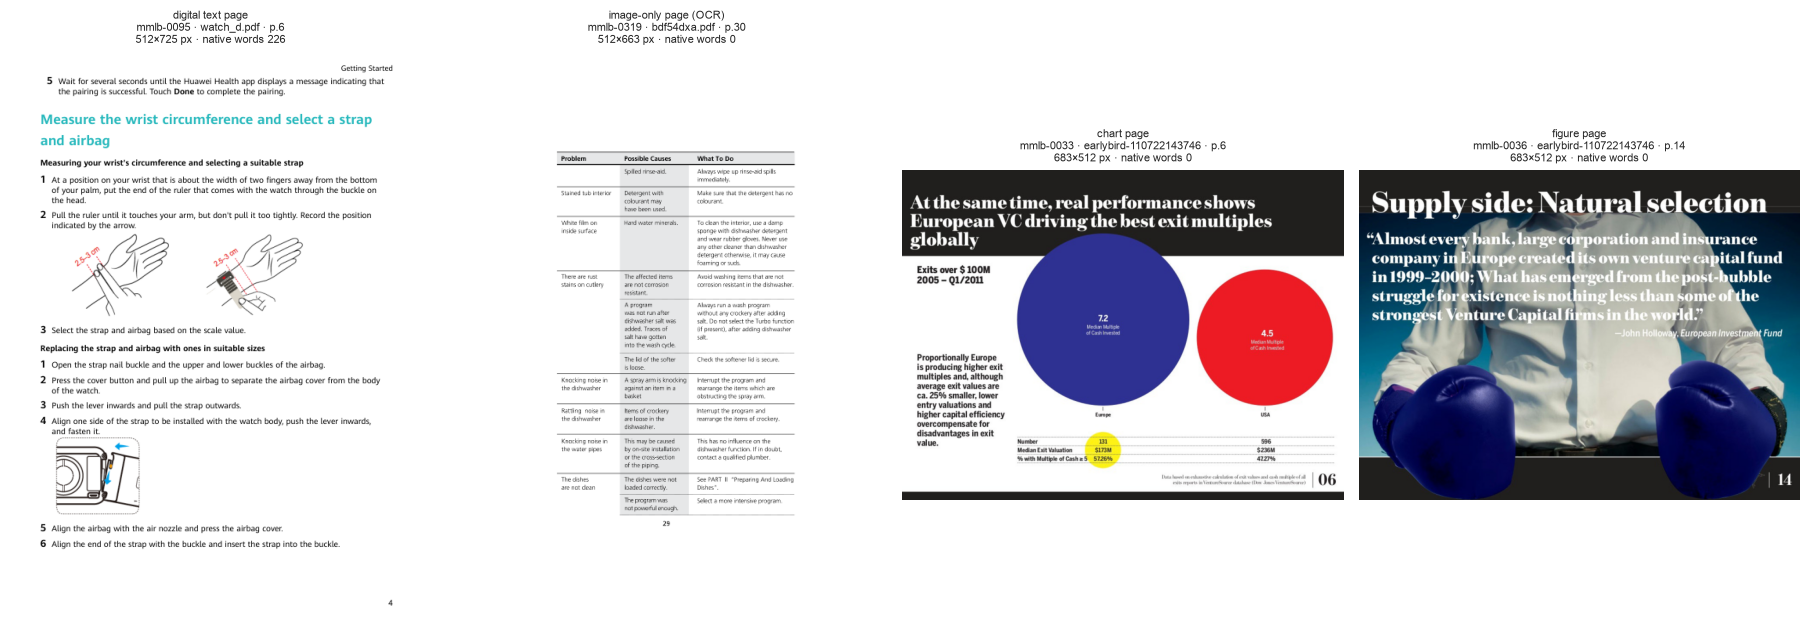

--- digital text page: text condition received (native, 1,414 chars), first 300 chars ---
 Getting Started 5 Wait for several seconds until the Huawei Health app displays a message indicating that the pairing is successful. Touch Done to complete the pairing. Measure the wrist circumference and select a strap and airbag Measuring your wrist's circumference and selecting a suitable strap 
--- image-only page (OCR): text condition received (OCR, 2,704 chars), first 300 chars ---
Problem Possible Causes What To Do Spilled rinse-aid. Always wipe up rinse-aid spills immediately. Stained tub interior Detergent with Make sure that the detergent has no colourant may colourant. have been used. White film on Hard water minerals. To clean the interior, use a damp. inside surface spo
--- chart page: text condition received (OCR, 2,129 chars), first 300 chars ---
At the same time,e real performanceGg shows European VCa | drivingee the best exito multiplese globally Exits over $ 100M 2005 - Q1/2011 

In [13]:
evidence_candidates = [
    (row.qid, row.doc_id, page, row.evidence_sources)
    for row in subset[subset["answerable"]].itertuples()
    for page in row.evidence_pages
]
SELECTION_RULES = {
    "digital text page": lambda doc, page, sources: page_lookup.loc[(doc, page), "native_words"] >= 30 and "Pure-text (Plain-text)" in sources,
    "image-only page (OCR)": lambda doc, page, sources: page_lookup.loc[(doc, page), "ocr_used"] and not VISUAL_SOURCES & set(sources),
    "chart page": lambda doc, page, sources: "Chart" in sources,
    "figure page": lambda doc, page, sources: "Figure" in sources,
}
representative, used = {}, set()
for label, rule in SELECTION_RULES.items():
    for qid, doc_id, page_number, sources in evidence_candidates:
        if (doc_id, page_number) not in used and rule(doc_id, page_number, sources):
            representative[label] = (qid, doc_id, page_number)
            used.add((doc_id, page_number))
            break

fig, axes = plt.subplots(1, len(representative), figsize=(4.6 * len(representative), 6.2))
for ax, (label, (qid, doc_id, page_number)) in zip(np.atleast_1d(axes), representative.items()):
    png = render_page_png(doc_id, page_number)
    ax.imshow(png_pixels(png))
    width, height = png_size(png)
    words = page_lookup.loc[(doc_id, page_number), "native_words"]
    ax.set_title(f"{label}\n{qid} · {doc_id[:22]} · p.{page_number}\n{width}×{height} px · native words {words}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

for label, (qid, doc_id, page_number) in representative.items():
    text = page_lookup.loc[(doc_id, page_number), "text"]
    source = "OCR" if page_lookup.loc[(doc_id, page_number), "ocr_used"] else "native"
    print(f"--- {label}: text condition received ({source}, {len(text):,} chars), first 300 chars ---")
    print(re.sub(r"\s+", " ", text)[:300])

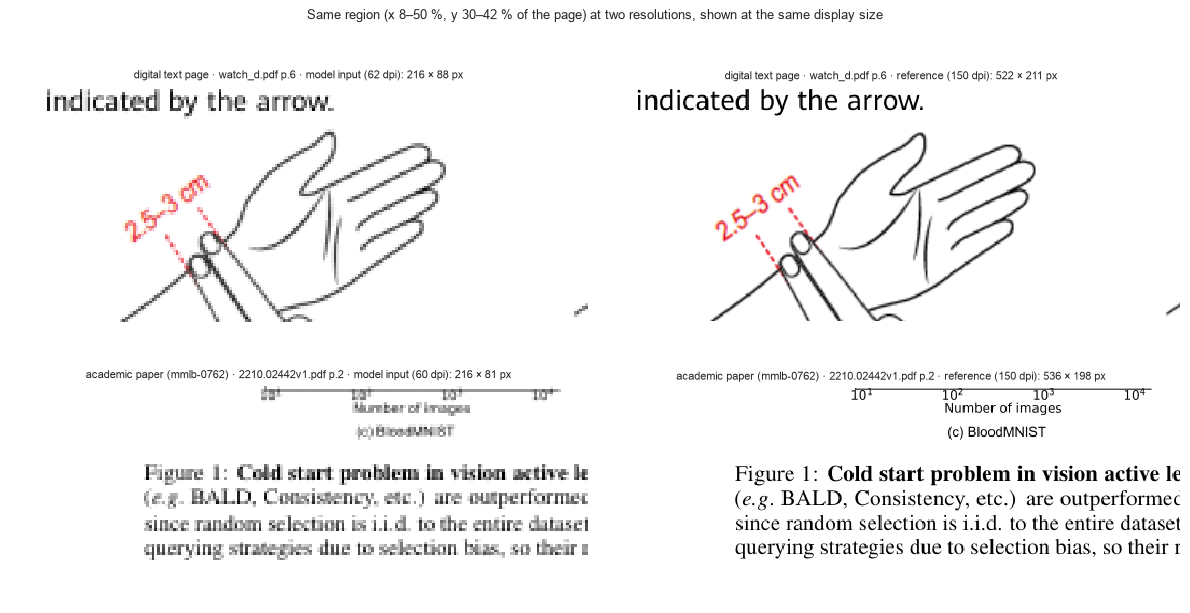

In [14]:
# Fine detail: the same page region at the model's resolution and at 150 dpi, for the digital text page above
# and for the first evidence page of the academic paper (the smallest body font in the subset).
paper_qid, paper_doc, paper_page = next(
    (qid, doc_id, page) for qid, doc_id, page, _ in evidence_candidates if reference.loc[qid, "doc_type"] == "Academic paper"
)
crop_cases = [("digital text page", *representative["digital text page"][1:]), (f"academic paper ({paper_qid})", paper_doc, paper_page)]

fig, axes = plt.subplots(len(crop_cases), 2, figsize=(12, 3.4 * len(crop_cases)))
for (label, doc_id, page_number), row_axes in zip(crop_cases, axes):
    with pymupdf.open(pdf_paths[doc_id]) as pdf:
        page = pdf_page(pdf, page_number)
        r = page.rect
        region = pymupdf.Rect(r.x0 + 0.08 * r.width, r.y0 + 0.30 * r.height, r.x0 + 0.50 * r.width, r.y0 + 0.42 * r.height)
        model_zoom = render_zoom(r.width, r.height)
        crops = {
            f"model input ({72 * model_zoom:.0f} dpi)": page.get_pixmap(matrix=pymupdf.Matrix(model_zoom, model_zoom), clip=region, alpha=False),
            "reference (150 dpi)": page.get_pixmap(matrix=pymupdf.Matrix(150 / 72, 150 / 72), clip=region, alpha=False),
        }
    for ax, (resolution, pixmap) in zip(row_axes, crops.items()):
        ax.imshow(np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.height, pixmap.width, pixmap.n), interpolation="nearest")
        ax.set_title(f"{label} · {doc_id[:24]} p.{page_number} · {resolution}: {pixmap.width} × {pixmap.height} px", fontsize=8)
        ax.axis("off")
fig.suptitle("Same region (x 8–50 %, y 30–42 % of the page) at two resolutions, shown at the same display size", fontsize=9)
plt.tight_layout()
plt.show()

### Interpretation

- **Slide pages keep what OCR destroys.** On the chart page (`mmlb-0033`, earlybird p.6), the image shows two bubbles labelled 7.2 and 4.5 and a small table with the highlighted values `$173M` and `$236M`. The OCR text the text condition received reads `exito multiplese … 7.2 … 45`. It drops the decimal point of 4.5 and loses which number belongs to which bubble. On the figure page (p.14), a white-on-photo quote is legible in the image, but OCR turned it into `ance"Almost everyh company ink f italfund…`.
- **Evidence that exists only as graphics.** On the digital text page (`watch_d` p.6, question `mmlb-0095`), the reference answer "2.5–3 cm" is a red label **inside the drawing**. The native text layer does not contain it (the text excerpt above has no "2.5"). That matches the text model's false abstention in Notebook 14. This page is a candidate for an image-only gain, a hypothesis to check, not a result.
- **The cost of 60 dpi.** In the crops, the watch-manual text and the academic paper's caption remain readable by eye but blurred, and small tick labels (`10²`, `10³`) are degraded. The image-only troubleshooting table (`bdf54dxa` p.30) uses a small font in a 512 × 663 image. For questions that hinge on a small word or digit, the image condition may be **disadvantaged** compared with exact native text.

## Step 6 — Page mapping and legibility, measured

Notebook 14 established that benchmark page `p` is PyMuPDF index `p − 1` (two independent checks). Here we verify that **the rendering path** respects that mapping and measure how much text survives at the model's resolution:

1. **Synthetic PDF:** three pages labelled `PAGE 1`, `PAGE 2`, `PAGE 3`. Rendering page `k` with our helper and OCR-ing the image must read `PAGE k`. This is a known-answer test of the whole path: page number → `pdf_page` → render → PNG.
2. **Failure case:** with plain indexing, page number 0 becomes `pdf[-1]`, which Python accepts and which silently returns the **last** page. `pdf_page` must refuse it.
3. **Real digital pages, mapping:** OCR `pdf_page(pdf, p)` at 150 dpi and compare it with the native text of pages `p − 1`, `p` and `p + 1`; page `p` must match best. A first version ran this check on the model-resolution image and **failed on the academic paper**: OCR read 0 % of its words at ≈ 60 dpi on every candidate page, so the comparison ended in a tie. The check is therefore done where OCR works (150 dpi, same `pdf_page` path). The cached model image is tied to the same page by the byte-identical re-render in Step 4.
4. **Legibility, per document:** OCR the exact model image and measure the share of the words of **the text the text condition received for that page** (native or OCR at 150 dpi) that it recovers. Three pages per document are sampled at even spacing. Tesseract is not GPT-4o-mini, so this is a **proxy**, but it is a measurement rather than a guess.

In [15]:
def ocr_png(png):
    """Tesseract OCR of a PNG through PyMuPDF (same engine and model as the text condition)."""
    ocr_pdf_bytes = pymupdf.Pixmap(png).pdfocr_tobytes(language="eng", tessdata=str(TESSDATA_DIR))
    with pymupdf.open("pdf", ocr_pdf_bytes) as ocr_pdf:
        return ocr_pdf[0].get_text()


synthetic = pymupdf.open()
for number in (1, 2, 3):
    synthetic.new_page(width=612, height=792).insert_text((72, 300), f"PAGE {number}", fontsize=96)

synthetic_rows = []
for number in (1, 2, 3):
    png, _ = render_png(pdf_page(synthetic, number))
    read = re.sub(r"\s+", " ", ocr_png(png)).strip()
    synthetic_rows.append({"requested page": number, "image size": "{} × {}".format(*png_size(png)), "OCR reads": read, "correct": read == f"PAGE {number}"})
display(pd.DataFrame(synthetic_rows))
assert all(row["correct"] for row in synthetic_rows)

# Failure case: page number 0 with plain indexing.
print("synthetic[0 - 1] silently returns:", repr(synthetic[0 - 1].get_text().strip()), "— the LAST page, no error")
try:
    pdf_page(synthetic, 0)
    raise AssertionError("page 0 was accepted")
except IndexError as error:
    print("pdf_page(synthetic, 0) raises IndexError:", error)
synthetic.close()

,requested page,image size,OCR reads,correct
0,1,512 × 663,PAGE 1,True
1,2,512 × 663,PAGE 2,True
2,3,512 × 663,PAGE 3,True


synthetic[0 - 1] silently returns: 'PAGE 3' — the LAST page, no error
pdf_page(synthetic, 0) raises IndexError: page 0 is not a 1-based page number of a 3-page PDF


In [16]:
WORD_PATTERN = re.compile(r"[a-z]{4,}")  # words of 4+ letters: distinctive, robust to OCR punctuation noise


def word_set(text):
    return set(WORD_PATTERN.findall(str(text).lower()))


def recovered_fraction(ocr_text, reference_text):
    reference_words = word_set(reference_text)
    return len(word_set(ocr_text) & reference_words) / len(reference_words) if reference_words else np.nan


def page_text_or_empty(doc_id, page_number, column):
    return page_lookup.loc[(doc_id, page_number), column] if (doc_id, page_number) in page_lookup.index else ""


# Three rendered pages per document, evenly spaced (deterministic).
sample = pd.concat(
    [group.iloc[np.unique(np.linspace(0, len(group) - 1, 3).round().astype(int))] for _, group in manifest.groupby("doc_id")]
)
legibility_rows = []
for row in sample.itertuples():
    ocr_model = ocr_png(render_page_png(row.doc_id, row.page))
    record = {
        "doc_id": row.doc_id[:28],
        "page": row.page,
        "text source": "OCR 150 dpi" if row.ocr_used else "native",
        "reference words": len(word_set(page_text_or_empty(row.doc_id, row.page, "text"))),
        "recovered at model resolution": recovered_fraction(ocr_model, page_text_or_empty(row.doc_id, row.page, "text")),
    }
    if not row.ocr_used:  # mapping check on pages with a native text layer, at 150 dpi
        with pymupdf.open(pdf_paths[row.doc_id]) as pdf:
            ocr_150 = ocr_png(pdf_page(pdf, row.page).get_pixmap(dpi=150, alpha=False).tobytes("png"))
        for label, offset in (("150 dpi vs native p-1", -1), ("150 dpi vs native p", 0), ("150 dpi vs native p+1", 1)):
            record[label] = recovered_fraction(ocr_150, page_text_or_empty(row.doc_id, row.page + offset, "native_text"))
    legibility_rows.append(record)
legibility = pd.DataFrame(legibility_rows)
display(legibility.round(2))

mapped = legibility.dropna(subset=["150 dpi vs native p"])
neighbours = mapped[["150 dpi vs native p-1", "150 dpi vs native p+1"]].max(axis=1).fillna(0)
assert (mapped["150 dpi vs native p"] > neighbours).all(), "pdf_page(p) matches a neighbouring page's native text better than page p"
print(f"Mapping check: on all {len(mapped)} sampled native-text pages, pdf_page(p) at 150 dpi matches the native text of page p best.")
display(legibility.groupby("doc_id")["recovered at model resolution"].median().round(2).rename("median share of words recovered by OCR at model resolution").to_frame())

,doc_id,page,text source,reference words,recovered at model resolution,150 dpi vs native p-1,150 dpi vs native p,150 dpi vs native p+1
0,2210.02442v1.pdf,1,native,198,0.07,NaN,0.95,0.29
1,2210.02442v1.pdf,14,native,149,0.05,0.22,0.99,0.49
2,2210.02442v1.pdf,24,native,42,0.00,0.14,0.90,NaN
3,PG_2020.05.21_International-,5,native,129,0.41,0.33,0.98,0.42
4,PG_2020.05.21_International-,14,native,95,0.40,0.45,1.00,0.76
5,PG_2020.05.21_International-,21,native,70,0.17,0.52,0.97,0.06
6,bdf54dxa.pdf,3,OCR 150 dpi,73,0.07,NaN,NaN,NaN
7,bdf54dxa.pdf,26,OCR 150 dpi,64,0.00,NaN,NaN,NaN
8,bdf54dxa.pdf,51,OCR 150 dpi,51,0.06,NaN,NaN,NaN
9,earlybird-110722143746-phpap,2,OCR 150 dpi,57,0.96,NaN,NaN,NaN


Mapping check: on all 9 sampled native-text pages, pdf_page(p) at 150 dpi matches the native text of page p best.


,median share of words recovered by OCR at model resolution
doc_id,
2210.02442v1.pdf,0.05
PG_2020.05.21_International-,0.40
bdf54dxa.pdf,0.06
earlybird-110722143746-phpap,0.96
germanwingsdigitalcrisisanal,0.83
watch_d.pdf,0.92


### Interpretation

- **Mapping is verified.** The synthetic pages read `PAGE 1/2/3` on pages 1/2/3. On all 9 sampled native-text pages, OCR of `pdf_page(p)` at 150 dpi recovers 0.90–1.00 of page `p`'s native words, more than for either neighbour in every case. The smallest margin is PG p.14: 1.00 for its own text against 0.76 for p.15, which shares much of its vocabulary. Together with the byte-identical re-render (Step 4), this ties every cached image to its intended physical page (validation items 1–2).
- **The off-by-one failure is silent** without a guard: `synthetic[0 - 1]` returned `PAGE 3`, the last page. `pdf_page` rejects page 0.
- **Legibility differs sharply by document.** The median share of words Tesseract recovers from the exact model image is high for the slide decks and the watch manual (`earlybird` 0.96, `watch_d` 0.92, `germanwings` 0.83), middling for the PG report (0.40), and near zero for the academic paper (0.05) and the scanned guidebook `bdf54dxa` (0.06). At 150 dpi the same native pages give 0.90–1.00.
- **How to read this.** Tesseract is a pessimistic proxy: the paper's caption in Step 5 is readable by eye at 60 dpi. Still, for 3 of the 6 documents the image condition receives visibly less legible text than the text condition did (native text, or OCR at 150 dpi for `bdf54dxa`). The analysis therefore reports results **per document with this legibility column**. A loss of image accuracy on those documents would be a resolution effect, not evidence that images are worse in general.
- **Consequence for H2.** Chart and figure questions sit mostly in the legible slide decks, text questions partly in the illegible documents. The evidence-type comparison is therefore confounded with legibility and document, and is reported as exploratory.

## Step 7 — Prompt and image-request builder (no network)

**Prompt.** The text system prompt from Notebook 14 is copied verbatim and verified against the baseline's saved prompt and its hash. The image prompt changes **only the words that describe the evidence** ("page excerpts" → "page images"). Output format, abstention phrase, citation rule and the "do not guess" instruction are identical.

**Message layout** (Chat Completions, image input):

```text
system: IMAGE_SYSTEM_PROMPT
user:   [text]  "Question: …\n\nPage images:"
        [text]  "[Page 6]"   [image]  data:image/png;base64,…  detail=high
        [text]  "[Page 27]"  [image]  …
        …                                   (supplied order = BM25 rank order)
```

Each image is preceded by its own `[Page N]` tag. The model can then cite physical page numbers exactly as in the text condition, and the citation checks work unchanged.

**What is never sent:** extracted or OCR text (validation below), the reference answer, `answer_format` (it would reveal unanswerability, see Notebook 14), evidence pages or sources. The builder receives only the question, the document and the page list, so it **cannot** leak a label.

**Logging without payloads.** A request carries ~0.5–1.5 MB of Base64. `loggable(request)` replaces each image with its SHA-256 and byte size. That is what gets saved and what the response-cache key is computed from. The full Base64 never reaches a file.

In [17]:
TEXT_SYSTEM_PROMPT = """You answer questions about a single PDF document using only the page excerpts provided.
Each excerpt starts with a tag [Page N], where N is the 1-based page number in the PDF.

Return a JSON object with exactly these keys:
  "answer": the shortest complete answer. Use a number (integer or decimal) when the answer is a number,
            and a JSON list when several items are asked for. If the excerpts do not contain the answer,
            use exactly the string "Not answerable".
  "cited_pages": a list of the page numbers N whose excerpts support the answer ([] if "Not answerable").

Do not use knowledge outside the excerpts. Do not guess."""

IMAGE_SYSTEM_PROMPT = """You answer questions about a single PDF document using only the page images provided.
Each page image is preceded by a tag [Page N], where N is the 1-based page number in the PDF.

Return a JSON object with exactly these keys:
  "answer": the shortest complete answer. Use a number (integer or decimal) when the answer is a number,
            and a JSON list when several items are asked for. If the page images do not contain the answer,
            use exactly the string "Not answerable".
  "cited_pages": a list of the page numbers N whose images support the answer ([] if "Not answerable").

Do not use knowledge outside the page images. Do not guess."""

# The text prompt is the one the baseline used: same string, same hash.
assert TEXT_SYSTEM_PROMPT == baseline_settings["system_prompt"]
assert hashlib.sha256((baseline_settings["prompt_version"] + TEXT_SYSTEM_PROMPT).encode()).hexdigest()[:12] == baseline_settings["prompt_hash"]
IMAGE_PROMPT_HASH = hashlib.sha256((SETTINGS["prompt_version"] + IMAGE_SYSTEM_PROMPT).encode()).hexdigest()[:12]

text_lines, image_lines = TEXT_SYSTEM_PROMPT.splitlines(), IMAGE_SYSTEM_PROMPT.splitlines()
assert len(text_lines) == len(image_lines)
prompt_diff = pd.DataFrame(
    [{"line": i + 1, "text prompt": t.strip(), "image prompt": m.strip()} for i, (t, m) in enumerate(zip(text_lines, image_lines)) if t != m]
)
# Only evidence-describing words change: undo the substitutions and the prompts must be identical.
undone = IMAGE_SYSTEM_PROMPT
for image_words, text_words in [("page images provided", "page excerpts provided"), ("Each page image is preceded by a tag", "Each excerpt starts with a tag"),
                                ("If the page images do not", "If the excerpts do not"), ("whose images support", "whose excerpts support"),
                                ("outside the page images", "outside the excerpts")]:
    undone = undone.replace(image_words, text_words)
assert undone == TEXT_SYSTEM_PROMPT
print(f"Text prompt verified against the baseline (hash {baseline_settings['prompt_hash']}). Image prompt hash {IMAGE_PROMPT_HASH}; "
      f"{len(prompt_diff)} of {len(text_lines)} lines differ, all in the wording that describes the evidence:")
prompt_diff

Text prompt verified against the baseline (hash f60729bf0b66). Image prompt hash 35ff2e8b91f9; 5 of 10 lines differ, all in the wording that describes the evidence:


,line,text prompt,image prompt
0,1,You answer questions about a single PDF document using only the pa...,You answer questions about a single PDF document using only the pa...
1,2,"Each excerpt starts with a tag [Page N], where N is the 1-based pa...","Each page image is preceded by a tag [Page N], where N is the 1-ba..."
2,6,and a JSON list when several items are asked for. If the excerpts ...,and a JSON list when several items are asked for. If the page imag...
3,8,"""cited_pages"": a list of the page numbers N whose excerpts support...","""cited_pages"": a list of the page numbers N whose images support t..."
4,10,Do not use knowledge outside the excerpts. Do not guess.,Do not use knowledge outside the page images. Do not guess.


In [18]:
def image_header(question):
    return f"Question: {question}\n\nPage images:"


def page_tag(page_number):
    return f"[Page {page_number}]"


def image_part(png):
    return {"type": "image_url", "image_url": {"url": "data:image/png;base64," + base64.b64encode(png).decode("ascii"), "detail": SETTINGS["image_detail"]}}


def build_image_user_content(question, doc_id, pages):
    """Question header, then one [Page N] tag followed by that page's image, in the supplied order. No page text."""
    content = [{"type": "text", "text": image_header(question)}]
    for page_number in pages:
        content.append({"type": "text", "text": page_tag(page_number)})
        content.append(image_part(render_page_png(doc_id, page_number)))
    return content


def build_request(user_content, system_prompt=IMAGE_SYSTEM_PROMPT):
    """Same request parameters as the text baseline (Notebook 14 build_request); only the content differs."""
    request = {
        "model": SETTINGS["model_name"],
        "messages": [{"role": "system", "content": system_prompt}, {"role": "user", "content": user_content}],
        "response_format": {"type": "json_object"},
        "max_completion_tokens": SETTINGS["max_output_tokens"],
    }
    if SETTINGS["temperature"] is not None:
        request["temperature"] = SETTINGS["temperature"]
    return request


def loggable(request):
    """The request with every image replaced by its SHA-256 and size: safe to save, no Base64."""

    def strip(part):
        if part.get("type") == "image_url":
            raw = base64.b64decode(part["image_url"]["url"].split(",", 1)[1])
            return {"type": "image", "sha256": hashlib.sha256(raw).hexdigest(), "bytes": len(raw), "detail": part["image_url"].get("detail")}
        return part

    messages = [
        {"role": m["role"], "content": m["content"] if isinstance(m["content"], str) else [strip(part) for part in m["content"]]}
        for m in request["messages"]
    ]
    return {**{key: value for key, value in request.items() if key != "messages"}, "messages": messages}


def request_fingerprint(request):
    """Identifies a request by everything that can change the reply (model, parameters, prompt, question, image hashes)."""
    return hashlib.sha256(json.dumps(loggable(request), sort_keys=True).encode()).hexdigest()


example_request = build_request(build_image_user_content(example["question"], example["doc_id"], example["retrieved_pages"]))
print(f"Example request for {example['qid']}: {len(json.dumps(example_request)) / 1e6:.2f} MB as JSON, "
      f"{len(json.dumps(loggable(example_request))):,} bytes as logged.")
print(json.dumps(loggable(example_request)["messages"][1]["content"][:5], indent=1)[:900])

Example request for mmlb-0033: 1.24 MB as JSON, 1,918 bytes as logged.
[
 {
  "type": "text",
  "text": "Question: How many more millions of dollars was the median exit valuation in the USA compared to Europe at the time of the presentation?\n\nPage images:"
 },
 {
  "type": "text",
  "text": "[Page 6]"
 },
 {
  "type": "image",
  "sha256": "28a109c4f1fc31fe240c994682cf027b4f53121c1838e422f9df5d3e06c9dd73",
  "bytes": 180760,
  "detail": "high"
 },
 {
  "type": "text",
  "text": "[Page 27]"
 },
 {
  "type": "image",
  "sha256": "08bb6af6e4320fdb0e599d1ce2e9ae2bec0fc23588c0965a67417ab9187ad65d",
  "bytes": 174708,
  "detail": "high"
 }
]


In [19]:
# Offline tests of the request builder, on every question of both conditions. No request leaves the machine.
built = 0
for row in subset.itertuples():
    for condition, pages_list in (("retrieved", row.retrieved_pages), ("oracle", row.oracle_pages)):
        if not pages_list:
            continue
        request = build_request(build_image_user_content(row.question, row.doc_id, pages_list))
        content = request["messages"][1]["content"]
        # 1. Layout: header, then (tag, image) per page, in exactly the supplied order.
        assert [part["type"] for part in content] == ["text"] + ["text", "image_url"] * len(pages_list)
        assert [part["text"] for part in content[1::2]] == [page_tag(p) for p in pages_list]
        # 2. Each image is exactly the rendered page it is labelled with.
        for page_number, part in zip(pages_list, content[2::2]):
            assert base64.b64decode(part["image_url"]["url"].split(",", 1)[1]) == render_page_png(row.doc_id, page_number)
        # 3. No extracted text: the only text parts are the question header and the page tags.
        assert [part["text"] for part in content if part["type"] == "text"] == [image_header(row.question)] + [page_tag(p) for p in pages_list]
        # 4. No label leaks: no annotation field name, and (answerable questions) the reference answer only if the
        #    question itself contains it. "Not answerable" is excluded: it is the abstention phrase both prompts define.
        logged = json.dumps(loggable(request))
        assert not any(field in logged for field in ("answer_format", "evidence_pages", "evidence_sources"))
        answer_text = str(row.answer).lower()
        if row.answerable and len(answer_text) >= 4 and not answer_text.replace(".", "").isdigit() and answer_text not in row.question.lower():
            assert answer_text not in logged.lower(), (row.qid, row.answer)
        # 5. The logged form carries no Base64 payload, and parameters match the baseline's.
        assert "base64" not in logged and len(logged) < 10_000
        assert request["model"] == SETTINGS["model_name"] and request["temperature"] == baseline_settings["temperature"]
        assert request["max_completion_tokens"] == baseline_settings["max_output_tokens"] and request["response_format"] == {"type": "json_object"}
        built += 1
print(f"Request-builder checks passed on {built} requests ({len(subset)} retrieved + {len(oracle_pages_saved)} oracle): "
      "page order, image identity, no page text, no labels, no Base64 in logs, same parameters as the text baseline.")

Request-builder checks passed on 97 requests (57 retrieved + 40 oracle): page order, image identity, no page text, no labels, no Base64 in logs, same parameters as the text baseline.


### Interpretation

The request builder has been tested on all 97 requests the full run would send (57 retrieved + 40 oracle), without any network call:

- the pages arrive in the frozen order, each preceded by its own `[Page N]` tag, and each image is byte-identical to the rendered page it is labelled with;
- no page text is sent: the only text parts are the question and the page tags, so condition B/D truly replaces text with pixels instead of adding pixels to text;
- no annotation reaches the model: no answer format, no evidence field, and the reference answer appears nowhere unless the question itself contains it;
- the logged form of a request is a few KB with image hashes instead of ~1 MB of Base64.

## Step 8 — Cost and context budget, before any call

**What:** estimate the prompt tokens of every request, check it against the 128k context window, and bound the cost of each run mode.

**How:** prompt tokens = text tokens (system prompt, question, page tags; counted with `tiktoken`'s `o200k_base`, the GPT-4o tokenizer, plus a small chat-format overhead) + image tokens (tile formula of the Concept section). Both tile rules are computed:

- `downscale_only`: images are only ever reduced, so our 512-px renders cost **2 tiles** (14,167 tokens);
- `upscale_to_768`: the short side is always set to 768 px, so they cost 4–6 tiles (25,501–36,835 tokens), whatever we render.

The two rules give very different answers to whether the experiment is feasible at all. The smoke test (Step 10) measures which one the API applies, and the batch uses only the measured rule.

**Cost formula** (upper bound: completion counted at the 400-token cap, cached-input discounts ignored):

$$\text{cost} \le \frac{0.15 \cdot \text{prompt tokens} + 0.60 \cdot 400 \cdot \text{requests}}{10^6}\ \text{USD (assumed list prices)}.$$

In [20]:
TILE_RULES = ("downscale_only", "upscale_to_768")


def tiles_for(width, height, rule):
    """512-px tiles counted for a high-detail image under the given resizing rule."""
    scale = min(1.0, 2048 / max(width, height))  # 1. fit within 2048 x 2048 (reduction only)
    width, height = width * scale, height * scale
    short_scale = 768 / min(width, height)  # 2. shortest side -> 768 px
    if rule == "upscale_to_768" or short_scale < 1:
        width, height = width * short_scale, height * short_scale
    return ceil(round(width, 6) / 512) * ceil(round(height, 6) / 512)  # 3. count 512-px tiles


def image_tokens(width, height, rule, detail=SETTINGS["image_detail"]):
    if detail == "low":
        return SETTINGS["image_base_tokens"]
    return SETTINGS["image_base_tokens"] + SETTINGS["image_tile_tokens"] * tiles_for(width, height, rule)


# Hand checks against OpenAI's documented gpt-4o examples (85 + 170 per tile): a 1024x1024 image is 4 tiles
# (765 tokens) and a 2048x4096 image is 6 tiles (1105 tokens). These hold under both rules (both images are large).
for rule in TILE_RULES:
    assert tiles_for(1024, 1024, rule) == 4 and 85 + 170 * tiles_for(1024, 1024, rule) == 765
    assert tiles_for(2048, 4096, rule) == 6 and 85 + 170 * tiles_for(2048, 4096, rule) == 1105
# Where the rules disagree: a small image.
assert tiles_for(512, 512, "downscale_only") == 1 and tiles_for(512, 512, "upscale_to_768") == 4

ENCODING = tiktoken.get_encoding("o200k_base") if tiktoken else None
MESSAGE_OVERHEAD_TOKENS = 9  # chat formatting (~3 per message + 3 for the reply); the smoke test measures the real residual


def count_text_tokens(text):
    return len(ENCODING.encode(text)) if ENCODING else ceil(len(text) / 4)


def estimate_request(question, doc_id, pages, rule, dims=None):
    """Estimated prompt tokens, context fit and cost upper bound for one image request."""
    dims = dims or [image_dims[(doc_id, page)] for page in pages]
    text_tokens = count_text_tokens(IMAGE_SYSTEM_PROMPT) + count_text_tokens(image_header(question)) + sum(count_text_tokens(page_tag(p)) for p in pages)
    text_tokens += MESSAGE_OVERHEAD_TOKENS
    image_total = sum(image_tokens(w, h, rule) for w, h in dims)
    prompt_tokens = text_tokens + image_total
    return {
        "text_tokens": text_tokens,
        "image_tokens": image_total,
        "prompt_tokens": prompt_tokens,
        "fits_context": prompt_tokens + SETTINGS["max_output_tokens"] <= SETTINGS["context_window_tokens"],
        "cost_usd_upper": (prompt_tokens * SETTINGS["price_usd_per_1m_input_tokens"] + SETTINGS["max_output_tokens"] * SETTINGS["price_usd_per_1m_output_tokens"]) / 1e6,
    }


per_shape = manifest.drop_duplicates(["width_px", "height_px"])[["doc_id", "width_px", "height_px"]].assign(
    **{f"tiles ({rule})": lambda f, rule=rule: [tiles_for(w, h, rule) for w, h in zip(f["width_px"], f["height_px"])] for rule in TILE_RULES},
    **{f"tokens ({rule})": lambda f, rule=rule: [image_tokens(w, h, rule) for w, h in zip(f["width_px"], f["height_px"])] for rule in TILE_RULES},
)
per_shape.assign(doc_id=per_shape["doc_id"].str[:28]).reset_index(drop=True)

,doc_id,width_px,height_px,tiles (downscale_only),tiles (upscale_to_768),tokens (downscale_only),tokens (upscale_to_768)
0,2210.02442v1.pdf,512,663,2,4,14167,25501
1,earlybird-110722143746-phpap,683,512,2,6,14167,36835
2,germanwingsdigitalcrisisanal,911,512,2,6,14167,36835
3,watch_d.pdf,512,725,2,6,14167,36835


In [21]:
estimate_rows = []
for row in subset.itertuples():
    for condition, pages_list in (("B. retrieved images", row.retrieved_pages), ("D. oracle images", row.oracle_pages)):
        if not pages_list:
            continue
        for rule in TILE_RULES:
            estimate_rows.append(
                {"qid": row.qid, "condition": condition, "rule": rule, "pages": len(pages_list), "pilot": row.qid in SETTINGS["pilot_qids"],
                 **estimate_request(row.question, row.doc_id, pages_list, rule)}
            )
estimates = pd.DataFrame(estimate_rows)


def budget_table(frame):
    feasible = frame[frame["fits_context"]]
    return pd.Series(
        {
            "requests": len(frame),
            "fit the context": len(feasible),
            "skipped (too large)": len(frame) - len(feasible),
            "min / max tokens per request": f"{frame['prompt_tokens'].min():,} / {frame['prompt_tokens'].max():,}",
            "prompt tokens (feasible)": int(feasible["prompt_tokens"].sum()),
            "cost upper bound (USD)": round(feasible["cost_usd_upper"].sum(), 3),
        }
    )


budget_rows = {}
for rule in TILE_RULES:
    for mode in ("pilot", "full"):
        for condition in ("B. retrieved images", "D. oracle images"):
            frame = estimates[(estimates["rule"] == rule) & (estimates["condition"] == condition)]
            if mode == "pilot":
                frame = frame[frame["pilot"]]
            budget_rows[(rule, mode, condition)] = budget_table(frame)
budget = pd.DataFrame(budget_rows).T
budget.index.names = ["tile rule", "mode", "condition"]
display(budget)

print("Requests too large for the context under `downscale_only` (the only rule under which a run can go ahead):")
display(estimates[(estimates["rule"] == "downscale_only") & ~estimates["fits_context"]][["qid", "condition", "pages", "image_tokens", "prompt_tokens"]])
smallest_upscale = estimates.loc[estimates["rule"] == "upscale_to_768", "prompt_tokens"].min()
print(f"Under `upscale_to_768` the smallest request needs {smallest_upscale:,} prompt tokens + {SETTINGS['max_output_tokens']} output "
      f"= {smallest_upscale + SETTINGS['max_output_tokens']:,} > {SETTINGS['context_window_tokens']:,}: no request fits.")

requests fit the context skipped (too large) min / max tokens per request prompt tokens (feasible)  \
tile rule      mode  condition                                                                                                                
downscale_only pilot B. retrieved images        5               5                   0              71,029 / 71,054                   355183   
                     D. oracle images           4               4                   0              71,029 / 71,054                   284150   
               full  B. retrieved images       57              57                   0              71,023 / 71,072                  4049166   
                     D. oracle images          40              38                   2             71,025 / 184,411                  2699499   
upscale_to_768 pilot B. retrieved images        5               0                   5            127,724 / 184,376                        0   
                     D. oracle images           4               0                   4            127,724 / 184,376                        0   
               full  B. retrieved images       57               0                  57            127,696 / 184,412                        0   
                     D. oracle images          40               0                  40            127,696 / 479,095                        0   

                                         cost upper bound (USD)  
tile rule      mode  condition                                   
downscale_only pilot B. retrieved images                  0.054  
                     D. oracle images                     0.044  
               full  B. retrieved images                  0.621  
                     D. oracle images                     0.414  
upscale_to_768 pilot B. retrieved images                    0.0  
                     D. oracle images                       0.0  
               full  B. retrieved images                    0.0  
                     D. oracle images                       0.0

Requests too large for the context under `downscale_only` (the only rule under which a run can go ahead):


,qid,condition,pages,image_tokens,prompt_tokens
10,mmlb-0035,D. oracle images,13,184171,184411
24,mmlb-0039,D. oracle images,10,141670,141891


Under `upscale_to_768` the smallest request needs 127,696 prompt tokens + 400 output = 128,096 > 128,000: no request fits.


### Interpretation

- **Under `downscale_only`** (our 512-px renders kept as sent), every page costs 2 tiles = 14,167 tokens, and a 5-page request is about 71k prompt tokens. All 57 retrieved requests and 38 of the 40 oracle requests fit the 128k context. The two counting questions with 13 and 10 evidence pages (`mmlb-0035`, `mmlb-0039`) do not (≈ 184k and ≈ 142k tokens), so they would be **skipped by protocol** in condition D. Estimated cost upper bound: **≈ $0.62 (B) + $0.41 (D) ≈ $1.04 for the full run** and ≈ $0.10 for the pilot (assumed list prices, completion counted at its 400-token cap).
- **Under `upscale_to_768`**, no request fits. Even the cheapest 5-page request (letter pages, 4 tiles each) needs ≈ 127.7k prompt tokens plus 400 output tokens, just over 128k. With gpt-4o-mini, 5 pages and high detail, the experiment would be **infeasible as designed**. The options would be `detail: "low"`, fewer pages (which breaks the k = 5 control), or a model with cheaper image tokens (which breaks the same-model control). That is a user decision, and the batch gate refuses to start in that case.
- The token rule is therefore not a detail: it decides whether this design can run at all. That is why the smoke test measures it before any benchmark question is sent.
- For comparison, the text condition used ~1.9k prompt tokens per question (108k for 57 questions in Notebook 14). Images multiply input tokens by ≈ 37× here.

## Step 9 — API plumbing: reused safety rules, plus three additions for images

**Reused verbatim from Notebook 14:** the readiness checks, the parser (`parse_model_output`), the error decision table (`classify_api_error`: credit exhaustion is *not* retried even though it is an HTTP 429; rate limits, timeouts and 5xx are retried at most `max_attempts` times with 2 s, 4 s waits; the SDK's own retries are off), the stop-at-first-unrecoverable-error rule, and the rule "no metric unless every question got a response".

**Three additions, each answering a problem specific to image requests:**

| addition | problem | how |
|---|---|---|
| **context-limit skip** | a 10- or 13-page oracle request may exceed 128k tokens: sending it wastes money and returns an error | estimated **before** the call from page count and image sizes; status `skipped_context_limit`; excluded from the population by protocol, never scored as wrong |
| **token pacing** | one image request is ~71k tokens, so 3 requests in a minute can exceed the account's tokens-per-minute limit, and 2 s / 4 s retries cannot recover from that | `TokenPacer` keeps the estimated tokens of the last 60 s under a budget: 80 % of the limit the API reports in the smoke test's `x-ratelimit-limit-tokens` header |
| **response cache** | re-executing the notebook (required by the completion standard) would pay for the same 97 requests again; a run stopped by an error would restart from zero | a successful reply is stored under the request fingerprint (model, parameters, prompt, question, image SHA-256) in `data/cache/mmlongbench_doc/vision_response_cache.jsonl`; a later identical request reuses it, and records say `source: cache` or `live` |

**Trade-off of the cache:** a cached answer is not a new sample, so run-to-run variation at temperature 0 (3–6 predictions out of 57 in Notebook 14) is not re-measured on re-execution. Set `reuse_cached_responses = False` to force fresh calls.

In [22]:
def generation_readiness():
    try:
        import openai  # noqa: F401

        has_package = True
    except ImportError:
        has_package = False
    checks = [
        ("provider is supported ('openai')", SETTINGS["model_provider"] == "openai", "the image condition is implemented for OpenAI only"),
        ("model snapshot chosen", bool(SETTINGS["model_name"]), "set VISUALDOC_VISION_MODEL or keep the baseline snapshot"),
        ("API key present", bool(os.getenv("OPENAI_API_KEY")), "set OPENAI_API_KEY in .env (the value is never printed)"),
        ("openai package installed", has_package, "pip install -e '.[llm]'"),
    ]
    return pd.DataFrame(checks, columns=["check", "ok", "how to fix"])


readiness = generation_readiness()
CREDENTIALS_READY = bool(readiness["ok"].all())
GENERATION_MODE = SETTINGS["vision_mode"]
GENERATION_READY = CREDENTIALS_READY and GENERATION_MODE != "off"
display(readiness)
print(f"Vision mode: {GENERATION_MODE!r} | configuration checks passed: {CREDENTIALS_READY} | GENERATION_READY = {GENERATION_READY}")
if GENERATION_MODE == "off":
    print("Mode 'off': no API call is made in this execution. Set VISUALDOC_VISION_MODE=smoke (then pilot, then full) to call the model.")

,check,ok,how to fix
0,provider is supported ('openai'),True,the image condition is implemented for OpenAI only
1,model snapshot chosen,True,set VISUALDOC_VISION_MODEL or keep the baseline snapshot
2,API key present,True,set OPENAI_API_KEY in .env (the value is never printed)
3,openai package installed,True,pip install -e '.[llm]'


Vision mode: 'off' | configuration checks passed: True | GENERATION_READY = False
Mode 'off': no API call is made in this execution. Set VISUALDOC_VISION_MODE=smoke (then pilot, then full) to call the model.


In [23]:
# Copied from Notebook 14 (Steps 9): parser, error classification, bounded retries. Only response_fields gains
# `cached_prompt_tokens` (prompt tokens the API billed at the cached-input rate), for cost accounting.
try:
    import openai
except ImportError:
    openai = None  # the readiness table above already reports the missing package


def parse_model_output(raw_text):
    """Return (prediction, cited_pages, error_message_or_None)."""
    try:
        payload = json.loads(raw_text)
        answer = payload["answer"]
        cited = [int(page) for page in payload.get("cited_pages", [])]
    except (json.JSONDecodeError, KeyError, TypeError, ValueError) as error:
        return "", [], f"unparseable model output: {error}"
    if isinstance(answer, str) and answer.strip().lower() == "not answerable":
        answer = "Not answerable"  # the F1 formula compares this exact string
    return answer, cited, None


assert parse_model_output('{"answer": "not answerable", "cited_pages": []}') == ("Not answerable", [], None)
assert parse_model_output('{"answer": 12, "cited_pages": ["4"]}') == (12, [4], None)
assert parse_model_output("The answer is 12 [Page 4]")[2].startswith("unparseable")
assert parse_model_output('{"answer": "Europe IPO", "cited_pa')[2].startswith("unparseable")

QUOTA_CODES = {"insufficient_quota", "credit_balance_exhausted", "billing_hard_limit_reached", "billing_not_active"}
SECRET_PATTERN = re.compile(r"sk-[A-Za-z0-9_\-\*]{4,}")


def sanitize(text, limit=300):
    return SECRET_PATTERN.sub("sk-<redacted>", str(text))[:limit]


def classify_api_error(error):
    """Return (category, retryable) for an exception raised by the OpenAI SDK."""
    if isinstance(error, openai.RateLimitError):
        if getattr(error, "code", None) in QUOTA_CODES or getattr(error, "type", None) in QUOTA_CODES:
            return "quota_or_billing", False  # same HTTP 429 as a rate limit, but waiting will not help
        return "rate_limit", True
    if isinstance(error, openai.AuthenticationError):
        return "authentication", False
    if isinstance(error, openai.PermissionDeniedError):
        return "permission", False
    if isinstance(error, openai.NotFoundError):
        return "model_access", False
    if isinstance(error, (openai.BadRequestError, openai.UnprocessableEntityError)):
        return "invalid_request", False
    if isinstance(error, openai.APIConnectionError):  # includes APITimeoutError
        return "network", True
    if isinstance(error, openai.InternalServerError) or (isinstance(error, openai.APIStatusError) and error.status_code in (408, 409)):
        return "server", True
    return "unexpected", False


def describe_api_error(error):
    category, retryable = classify_api_error(error)
    return {
        "category": category,
        "retryable": retryable,
        "exception": type(error).__name__,
        "status_code": getattr(error, "status_code", None),
        "code": getattr(error, "code", None),
        "type": getattr(error, "type", None),
        "message": sanitize(getattr(error, "message", error)),
        "request_id": getattr(error, "request_id", None),
    }


def call_with_retries(create, request, max_attempts=SETTINGS["max_attempts"], sleep=time.sleep):
    """Call create(**request); retry only transient errors, waiting 2 s, 4 s, ...
    Returns (response or None, list of failed-attempt records, latency in seconds of the last attempt).
    Exceptions that are not OpenAI errors (bugs in this notebook) are not caught."""
    failures = []
    for attempt in range(1, max_attempts + 1):
        started = time.perf_counter()
        try:
            response = create(**request)
            return response, failures, round(time.perf_counter() - started, 3)
        except openai.OpenAIError as error:
            latency = round(time.perf_counter() - started, 3)
            failures.append(describe_api_error(error))
            if not failures[-1]["retryable"] or attempt == max_attempts:
                return None, failures, latency
            sleep(2**attempt)


RESPONSE_FIELDS = ("raw_response", "finish_reason", "served_model", "prompt_tokens", "completion_tokens", "cached_prompt_tokens")


def response_fields(response):
    usage = response.usage
    details = getattr(usage, "prompt_tokens_details", None) if usage else None
    return {
        "raw_response": response.choices[0].message.content or "",
        "finish_reason": response.choices[0].finish_reason,
        "served_model": response.model,
        "prompt_tokens": usage.prompt_tokens if usage else None,
        "completion_tokens": usage.completion_tokens if usage else None,
        "cached_prompt_tokens": getattr(details, "cached_tokens", None),
    }


EXTERNAL_ACTION = {
    "quota_or_billing": "Add credits or raise the budget limit of the organization/project that owns this key. No code change can fix this.",
    "authentication": "The key was rejected: create a new key and replace OPENAI_API_KEY in .env.",
    "permission": "The key's project may not use this model or image input: allow it in the project settings.",
    "model_access": "Check the model snapshot name and that the key's project has access to it.",
    "invalid_request": "A request parameter or the image payload is not accepted: read `param` and `message` in the failure record.",
    "rate_limit": "Transient: retry later, or lower the pacing budget.",
    "network": "Transient: check the connection and retry.",
    "server": "Transient: OpenAI server error, retry later.",
    "unexpected": "Unclassified error: inspect `exception` and `message`.",
}
print("Parser, error classification and bounded-retry helpers defined." if openai else "openai is not installed: generation helpers are unusable.")

Parser, error classification and bounded-retry helpers defined.


In [24]:
class TokenPacer:
    """Keeps the estimated prompt tokens sent in any 60-second window under `tokens_per_minute`.
    A request waits (sleep) instead of triggering the account's tokens-per-minute limit."""

    def __init__(self, tokens_per_minute, clock=time.monotonic, sleep=time.sleep):
        self.tokens_per_minute, self.clock, self.sleep = tokens_per_minute, clock, sleep
        self.window = deque()  # (send time, estimated tokens)
        self.waited_s = 0.0

    def wait(self, tokens):
        while True:
            now = self.clock()
            while self.window and now - self.window[0][0] >= 60:
                self.window.popleft()
            if not self.window or sum(t for _, t in self.window) + tokens <= self.tokens_per_minute:
                break
            pause = 60 - (now - self.window[0][0])
            self.sleep(pause)
            self.waited_s += pause
        self.window.append((self.clock(), tokens))


RESPONSE_CACHE_PATH = CACHE_DIR / "vision_response_cache.jsonl"


def load_response_cache(path):
    return {record["fingerprint"]: record for record in read_jsonl(path)} if path.is_file() else {}


def append_to_cache(path, fingerprint, fields, latency):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "a") as handle:
        stamp = datetime.now(timezone.utc).isoformat(timespec="seconds")
        handle.write(json.dumps({"fingerprint": fingerprint, "saved_at": stamp, "latency_s": latency, **fields}) + "\n")


def generate_image_answers(rows, create, *, pages_for, tile_rule, pacer=None, cache=None, cache_path=None, sleep=time.sleep):
    """One record per question (no Base64 in records). Order of decisions for each question:
    1. too large for the context -> 'skipped_context_limit' (no call);  2. batch already stopped -> 'not_attempted';
    3. identical request in the cache -> reuse it;  4. otherwise pace, call with bounded retries, cache the reply.
    The first question whose call still fails stops the batch (Notebook 14 rule)."""
    records, stop_reason = [], None
    for row in rows:
        pages_list = list(pages_for(row))
        estimate = estimate_request(row.question, row.doc_id, pages_list, tile_rule)
        record = {
            "qid": row.qid, "supplied_pages": pages_list, "requested_model": SETTINGS["model_name"], "image_detail": SETTINGS["image_detail"],
            "render": RENDER_LABEL, "tile_rule": tile_rule, "estimated_prompt_tokens": estimate["prompt_tokens"],
            "status": "not_attempted", "source": None, "pred": "", "cited_pages": [], "raw_response": None,
        }
        if not estimate["fits_context"]:
            record["status"] = "skipped_context_limit"  # decided from page count and image sizes only, before any call
        elif stop_reason is None:
            request = build_request(build_image_user_content(row.question, row.doc_id, pages_list))
            fingerprint = request_fingerprint(request)
            logged_images = [part for part in loggable(request)["messages"][1]["content"] if part.get("type") == "image"]
            record.update(fingerprint=fingerprint, image_sha256=[part["sha256"][:16] for part in logged_images])
            cached = cache.get(fingerprint) if cache is not None and SETTINGS["reuse_cached_responses"] else None
            if cached is not None:
                record.update({field: cached.get(field) for field in RESPONSE_FIELDS}, source="cache", attempts=0, latency_s=cached.get("latency_s"), failed_attempts=[])
            else:
                if pacer is not None:
                    pacer.wait(estimate["prompt_tokens"])
                response, failures, latency = call_with_retries(create, request, sleep=sleep)
                record.update(source="live", attempts=len(failures) + (response is not None), latency_s=latency, failed_attempts=failures)
                if response is None:
                    record.update(status="api_error", error_category=failures[-1]["category"])
                    stop_reason = f"{failures[-1]['category']} at {row.qid} after {len(failures)} attempt(s)"
                else:
                    fields = response_fields(response)
                    record.update(fields)
                    if cache is not None:
                        cache[fingerprint] = {**fields, "latency_s": latency}
                        if cache_path is not None:
                            append_to_cache(cache_path, fingerprint, fields, latency)
            if record["raw_response"] is not None:
                pred, cited, parse_error = parse_model_output(record["raw_response"])
                record.update(pred=pred, cited_pages=cited, parse_error=parse_error, status="ok" if parse_error is None else "parse_error")
        records.append(record)
    return records, stop_reason


SKIPPED_BY_PROTOCOL = {"skipped_context_limit"}


def generation_outcome(records, population_qids):
    """Complete = every question not skipped by protocol received a model response (ok or parse_error)."""
    status = pd.Series({r["qid"]: r["status"] for r in records}, dtype=object).reindex(population_qids).fillna("not_attempted")
    considered = status[~status.isin(SKIPPED_BY_PROTOCOL)]
    return bool(len(considered)) and bool(considered.isin(["ok", "parse_error"]).all()), status.value_counts().to_dict()


print("Pacing, response cache and image batch helpers defined. Cache file:", RESPONSE_CACHE_PATH.relative_to(PROJECT_ROOT),
      f"({len(load_response_cache(RESPONSE_CACHE_PATH))} cached replies)")

Pacing, response cache and image batch helpers defined. Cache file: data/cache/mmlongbench_doc/vision_response_cache.jsonl (71 cached replies)


**Offline tests with mocked API responses.** No request leaves the machine. The mocks are real SDK exception and `ChatCompletion` objects built from fixed bodies; the credit-exhausted body is the one recorded in Notebook 14's failed run. The questions and page images are real, because the request builder runs for real. Only the replies are mocked. These are **interface tests**: their replies never enter any result, and the cache test writes to a temporary folder, not to the real cache.

In [25]:
if openai is None:
    print("Skipped: openai is not installed, so the SDK exception classes cannot be mocked.")
else:
    import httpx
    from openai.types.chat import ChatCompletion

    MOCK_REQUEST = httpx.Request("POST", "https://api.openai.com/v1/chat/completions")

    def mock_status_error(cls, status, body):
        response = httpx.Response(status, request=MOCK_REQUEST, headers={"x-request-id": "req_mock"})
        return cls(f"Error code: {status} - {body}", response=response, body=body)

    def mock_completion(content, finish_reason="stop", prompt_tokens=71_000):
        return ChatCompletion.model_validate(
            {
                "id": "chatcmpl-mock", "object": "chat.completion", "created": 0, "model": "mock-model-snapshot",
                "choices": [{"index": 0, "finish_reason": finish_reason, "message": {"role": "assistant", "content": content}}],
                "usage": {"prompt_tokens": prompt_tokens, "completion_tokens": 10, "total_tokens": prompt_tokens + 10, "prompt_tokens_details": {"cached_tokens": 0}},
            }
        )

    def scripted(*outcomes):
        """Stand-in for client.chat.completions.create: replays outcomes in order, records each request."""
        calls = []

        def create(**request):
            calls.append(request)
            outcome = outcomes[min(len(calls), len(outcomes)) - 1]
            if isinstance(outcome, Exception):
                raise outcome
            return outcome

        return create, calls

    QUOTA_BODY = {"message": "You have no credits remaining.", "type": "insufficient_quota", "param": None, "code": "credit_balance_exhausted"}
    quota_error = mock_status_error(openai.RateLimitError, 429, QUOTA_BODY)
    rate_error = mock_status_error(openai.RateLimitError, 429, {"message": "Rate limit reached for tokens", "type": "tokens", "param": None, "code": "rate_limit_exceeded"})
    server_error = mock_status_error(openai.InternalServerError, 500, {"message": "The server had an error.", "type": "server_error", "param": None, "code": None})
    image_error = mock_status_error(openai.BadRequestError, 400, {"message": "Invalid image.", "type": "invalid_request_error", "param": None, "code": "invalid_image"})
    for error, expected in [(quota_error, ("quota_or_billing", False)), (rate_error, ("rate_limit", True)), (server_error, ("server", True)),
                            (image_error, ("invalid_request", False)), (openai.APITimeoutError(request=MOCK_REQUEST), ("network", True))]:
        assert classify_api_error(error) == expected, (type(error).__name__, classify_api_error(error))

    test_rows = list(subset[subset["qid"].isin(["mmlb-0033", "mmlb-0034", "mmlb-0038", "mmlb-0041"])].itertuples())
    test_qids = [row.qid for row in test_rows]
    retrieved = lambda row: row.retrieved_pages
    no_sleep = lambda seconds: None

    # A. Credits exhausted on question 1: exactly one request, the rest not attempted, metrics gated.
    create, calls = scripted(quota_error)
    records, stop = generate_image_answers(test_rows, create, pages_for=retrieved, tile_rule="downscale_only", sleep=no_sleep)
    assert len(calls) == 1 and [r["status"] for r in records] == ["api_error", "not_attempted", "not_attempted", "not_attempted"]
    assert stop.startswith("quota_or_billing") and generation_outcome(records, test_qids)[0] is False

    # B. Transient token rate limit, then success: one retry after 2 s.
    waits = []
    create, calls = scripted(rate_error, mock_completion('{"answer": 63, "cited_pages": [6]}'))
    records, stop = generate_image_answers(test_rows[:1], create, pages_for=retrieved, tile_rule="downscale_only", sleep=waits.append)
    assert stop is None and len(calls) == 2 and waits == [2] and records[0]["status"] == "ok" and records[0]["attempts"] == 2

    # C. Persistent server error: bounded at max_attempts requests (waits 2 s, 4 s), then the batch stops.
    waits = []
    create, calls = scripted(server_error)
    records, stop = generate_image_answers(test_rows[:2], create, pages_for=retrieved, tile_rule="downscale_only", sleep=waits.append)
    assert len(calls) == SETTINGS["max_attempts"] == 3 and waits == [2, 4] and [r["status"] for r in records] == ["api_error", "not_attempted"]

    # D. Replies: parsed answer, abstention, truncated JSON (a model failure: parse_error, kept and scored 0).
    create, calls = scripted(
        mock_completion('{"answer": 63, "cited_pages": [6]}'),
        mock_completion('{"answer": "not answerable", "cited_pages": []}'),
        mock_completion('{"answer": "Europe IPO", "cited_pa', finish_reason="length"),
    )
    records, stop = generate_image_answers(test_rows[:3], create, pages_for=retrieved, tile_rule="downscale_only")
    assert [r["status"] for r in records] == ["ok", "ok", "parse_error"] and records[1]["pred"] == "Not answerable"
    assert records[0]["served_model"] == "mock-model-snapshot" and records[0]["prompt_tokens"] == 71_000 and records[0]["source"] == "live"
    assert generation_outcome(records, test_qids[:3]) == (True, {"ok": 2, "parse_error": 1})

    # E. The request sent is the image request: model, detail, one image per supplied page, in order, no page text.
    sent = calls[0]
    assert sent["model"] == SETTINGS["model_name"] and sent["messages"][0]["content"] == IMAGE_SYSTEM_PROMPT
    images = [part for part in sent["messages"][1]["content"] if part["type"] == "image_url"]
    assert len(images) == len(test_rows[0].retrieved_pages) and all(part["image_url"]["detail"] == SETTINGS["image_detail"] for part in images)

    # F. Records are safe to save: no Base64, no data URL.
    assert all("base64" not in json.dumps(r, default=str) and "data:image" not in json.dumps(r, default=str) for r in records)

    # G. Response cache: a second pass makes zero calls and returns identical predictions; the cache file has no Base64.
    with tempfile.TemporaryDirectory() as temporary:
        temp_cache_path = Path(temporary) / "cache.jsonl"
        temp_cache = {}
        create, calls = scripted(mock_completion('{"answer": 63, "cited_pages": [6]}'), mock_completion('{"answer": "Not answerable", "cited_pages": []}'))
        first, _ = generate_image_answers(test_rows[:2], create, pages_for=retrieved, tile_rule="downscale_only", cache=temp_cache, cache_path=temp_cache_path)
        create_again, calls_again = scripted(server_error)  # would fail if it were called
        second, _ = generate_image_answers(test_rows[:2], create_again, pages_for=retrieved, tile_rule="downscale_only", cache=load_response_cache(temp_cache_path))
        assert len(calls) == 2 and len(calls_again) == 0
        assert [r["pred"] for r in first] == [r["pred"] for r in second] and [r["source"] for r in second] == ["cache", "cache"]
        assert "base64" not in temp_cache_path.read_text()

    # H. Context limit: the 13-page oracle request is skipped without a call; the outcome excludes it by protocol.
    big = subset[subset["qid"] == "mmlb-0035"].iloc[0]
    create, calls = scripted(mock_completion('{"answer": 1}'))
    records, stop = generate_image_answers([next(subset[subset["qid"] == "mmlb-0035"].itertuples())], create, pages_for=lambda row: row.oracle_pages, tile_rule="downscale_only")
    assert len(big["oracle_pages"]) == 13 and records[0]["status"] == "skipped_context_limit" and len(calls) == 0
    assert generation_outcome(records + [{"qid": "x", "status": "ok"}], ["mmlb-0035", "x"]) == (True, {"skipped_context_limit": 1, "ok": 1})

    # I. Pacer: budget 100k/min, three 60k requests -> the 2nd and 3rd each wait for the window to clear.
    fake_time = [0.0]
    pacer_waits = []
    def fake_sleep(seconds):
        pacer_waits.append(round(seconds, 6))
        fake_time[0] += seconds
    pacer = TokenPacer(100_000, clock=lambda: fake_time[0], sleep=fake_sleep)
    for _ in range(3):
        pacer.wait(60_000)
    assert pacer_waits == [60.0, 60.0] and pacer.waited_s == 120.0

    # J. A bug in our own code is not mistaken for an API failure: it propagates.
    def broken_create(**request):
        raise KeyError("bug")
    try:
        generate_image_answers(test_rows[:1], broken_create, pages_for=retrieved, tile_rule="downscale_only")
        raise AssertionError("a non-API exception was swallowed")
    except KeyError:
        pass

    print("Mocked API tests passed: classification, quota stop, bounded retries, parsing, request content, Base64-free records, "
          "response cache, context-limit skip, token pacing, bug propagation.")

Mocked API tests passed: classification, quota stop, bounded retries, parsing, request content, Base64-free records, response cache, context-limit skip, token pacing, bug propagation.


## Step 10 — Populations, smoke test and batch gate

**Populations by mode.**

| mode | B: retrieved images | D: oracle images | API calls |
|---|---|---|---|
| `off` (default) | — | — | none |
| `smoke` | — | — | 1 synthetic page |
| `pilot` | the 5 pilot questions of Notebook 14 (4 answerable + 1 unanswerable) | their 4 answerable questions | 1 + 5 + 4 |
| `full` | all 57 questions | the 40 answerable questions (minus any skipped by the context limit) | 1 + 57 + ≤ 40 |

The pilot questions are read from the baseline settings, so B's pilot is paired with exactly the text answers Notebook 14 produced for them.

**Smoke test.** One real request on a **synthetic** page, rendered from a PDF created in memory with the sentence "This report was published in 2019 by the research team." It goes through the same render box, prompt and parameters. It checks four things: (1) credentials, credit and access to the snapshot; (2) that the image actually reaches the model (expected answer `2019`, citing page 1); (3) **which tile rule the API applies**, by comparing `usage.prompt_tokens` with the two predictions; (4) the account's tokens-per-minute limit, from the response headers. Its reply never enters any result. Expected cost < $0.01.

**Batch gate.** Generation for B and D starts only if every row of the gate table is true: mode is `pilot`/`full`, configuration ready, smoke answer correct, tile rule measured, design feasible under that rule (every B request fits the context), and estimated cost of uncached requests ≤ `max_estimated_live_cost_usd`.

In [26]:
pilot_frame = subset[subset["qid"].isin(SETTINGS["pilot_qids"])]
assert len(pilot_frame) == len(SETTINGS["pilot_qids"]) == 5 and int((~pilot_frame["answerable"]).sum()) == 1

population = pilot_frame if GENERATION_MODE == "pilot" else subset  # off/smoke: shown for reference, nothing is sent
retrieved_population = population.assign(pages=population["retrieved_pages"])
oracle_population = population[population["oracle_pages"].notna()].assign(pages=lambda frame: frame["oracle_pages"])

print(f"Mode {GENERATION_MODE!r}: condition B population {len(retrieved_population)} questions "
      f"({int(retrieved_population['answerable'].sum())} answerable, {int((~retrieved_population['answerable']).sum())} unanswerable); "
      f"condition D population {len(oracle_population)} answerable questions.")
pilot_frame[["qid", "doc_id", "answer_format", "answerable", "evidence_group", "retrieval_group", "retrieved_pages", "oracle_pages"]]

Mode 'off': condition B population 57 questions (40 answerable, 17 unanswerable); condition D population 40 answerable questions.


,qid,doc_id,answer_format,answerable,evidence_group,retrieval_group,retrieved_pages,oracle_pages
3,mmlb-0036,earlybird-110722143746-phpapp02_95.pdf,Int,True,chart or figure,no evidence in top 5,"[38, 30, 2, 5, 7]","[19, 33, 14, 20, 37]"
23,mmlb-0355,PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,Str,True,chart or figure,all evidence in top 5,"[19, 21, 20, 6, 7]","[19, 21, 20, 6, 7]"
36,mmlb-0731,germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95...,List,True,chart or figure,all evidence in top 5,"[8, 7, 18, 13, 6]","[8, 7, 18, 13, 6]"
39,mmlb-0734,germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95...,None,False,unanswerable,unanswerable,"[19, 18, 23, 7, 4]",None
41,mmlb-0736,germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95...,Int,True,chart or figure,all evidence in top 5,"[14, 19, 6, 16, 4]","[14, 19, 6, 16, 4]"


Smoke page 512 × 663 px; predicted prompt tokens: {'downscale_only': 14337, 'upscale_to_768': 25671}
Smoke test: not run | answer correct: False


,value
status,not run


Not run: the smoke test needs VISUALDOC_VISION_MODE=smoke, pilot or full, and passing configuration checks.


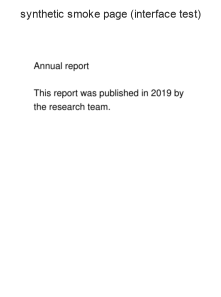

In [27]:
# The synthetic smoke page: an interface test with a known answer. It never enters the results.
SMOKE_QUESTION = "In which year was the report published?"
smoke_pdf = pymupdf.open()
smoke_page = smoke_pdf.new_page(width=612, height=792)  # letter, like two of the benchmark documents
smoke_page.insert_textbox(pymupdf.Rect(72, 100, 540, 500), "Annual report\n\nThis report was published in 2019 by the research team.", fontsize=28)
SMOKE_PNG, _ = render_png(smoke_page)
smoke_pdf.close()
SMOKE_DIMS = png_size(SMOKE_PNG)
smoke_request = build_request([{"type": "text", "text": image_header(SMOKE_QUESTION)}, {"type": "text", "text": page_tag(1)}, image_part(SMOKE_PNG)])
smoke_predicted = {rule: estimate_request(SMOKE_QUESTION, None, [1], rule, dims=[SMOKE_DIMS])["prompt_tokens"] for rule in TILE_RULES}
print(f"Smoke page {SMOKE_DIMS[0]} × {SMOKE_DIMS[1]} px; predicted prompt tokens: {smoke_predicted}")

smoke_record, RATE_LIMIT_HEADERS, client = {"status": "not run"}, {}, None
if GENERATION_READY:
    from openai import OpenAI

    client = OpenAI(max_retries=0, timeout=SETTINGS["request_timeout_s"])  # the SDK's silent retries are off

    def create_capturing_headers(**request):
        raw = client.chat.completions.with_raw_response.create(**request)
        RATE_LIMIT_HEADERS.update({key: value for key, value in raw.headers.items() if key.lower().startswith("x-ratelimit-")})
        return raw.parse()

    response, failures, latency = call_with_retries(create_capturing_headers, smoke_request)
    smoke_record = {"requested_model": SETTINGS["model_name"], "image_px": SMOKE_DIMS, "predicted_prompt_tokens": smoke_predicted,
                    "attempts": len(failures) + (response is not None), "latency_s": latency, "failed_attempts": failures}
    if response is None:
        smoke_record.update(status="api_error", error_category=failures[-1]["category"])
    else:
        smoke_record.update(response_fields(response))
        pred, cited, parse_error = parse_model_output(smoke_record["raw_response"])
        smoke_record.update(pred=pred, cited_pages=cited, parse_error=parse_error, status="ok" if parse_error is None else "parse_error")
SMOKE_OK = smoke_record["status"] == "ok" and str(smoke_record.get("pred")) == "2019"

print("Smoke test:", smoke_record["status"], "| answer correct:", SMOKE_OK)
display(pd.Series({k: v for k, v in smoke_record.items() if k not in ("failed_attempts", "raw_response", "predicted_prompt_tokens")}, dtype=object).to_frame("value"))
if smoke_record.get("failed_attempts"):
    display(pd.DataFrame(smoke_record["failed_attempts"]))
if smoke_record["status"] == "api_error":
    print("REQUIRED ACTION:", EXTERNAL_ACTION[smoke_record["error_category"]])
if smoke_record["status"] == "not run":
    print("Not run: the smoke test needs VISUALDOC_VISION_MODE=smoke, pilot or full, and passing configuration checks.")

fig, ax = plt.subplots(figsize=(2.6, 3.4))
ax.imshow(png_pixels(SMOKE_PNG))
ax.set_title("synthetic smoke page (interface test)", fontsize=8)
ax.axis("off")
plt.show()

In [28]:
TOKEN_TOLERANCE = 300  # the two rules differ by 11,334 tokens on the smoke page; text-token estimates are within tens of tokens

MEASURED_TILE_RULE = None
if smoke_record.get("prompt_tokens") is not None:
    smoke_rule_table = pd.DataFrame(
        [{"rule": rule, "predicted prompt tokens": predicted, "measured prompt tokens": smoke_record["prompt_tokens"],
          "measured − predicted": smoke_record["prompt_tokens"] - predicted} for rule, predicted in smoke_predicted.items()]
    )
    display(smoke_rule_table)
    matches = smoke_rule_table.loc[smoke_rule_table["measured − predicted"].abs() <= TOKEN_TOLERANCE, "rule"].tolist()
    MEASURED_TILE_RULE = matches[0] if len(matches) == 1 else None
    smoke_record["measured_tile_rule"] = MEASURED_TILE_RULE
    if MEASURED_TILE_RULE is None:
        print("The measured prompt tokens match NEITHER tile rule: the cost model is wrong, so no batch can be bounded. Inspect before continuing.")

limit_tokens = RATE_LIMIT_HEADERS.get("x-ratelimit-limit-tokens")
PACING_TPM = int(0.8 * int(limit_tokens)) if limit_tokens and str(limit_tokens).isdigit() else SETTINGS["default_tokens_per_minute"]
response_cache = load_response_cache(RESPONSE_CACHE_PATH)


def live_plan(population_frame, rule):
    """Which requests of a population would be skipped, served from the cache, or sent live, and their cost bound."""
    plan = Counter()
    cost = 0.0
    for row in population_frame.itertuples():
        estimate = estimate_request(row.question, row.doc_id, row.pages, rule)
        if not estimate["fits_context"]:
            plan["skipped (context)"] += 1
        elif SETTINGS["reuse_cached_responses"] and request_fingerprint(build_request(build_image_user_content(row.question, row.doc_id, row.pages))) in response_cache:
            plan["cached"] += 1
        else:
            plan["live"] += 1
            cost += estimate["cost_usd_upper"]
    return plan, cost


if MEASURED_TILE_RULE is not None:
    plan_b, cost_b = live_plan(retrieved_population, MEASURED_TILE_RULE)
    plan_d, cost_d = live_plan(oracle_population, MEASURED_TILE_RULE)
    LIVE_COST_ESTIMATE = cost_b + cost_d
    DESIGN_FEASIBLE = plan_b["skipped (context)"] == 0
    display(pd.DataFrame({"B. retrieved images": plan_b, "D. oracle images": plan_d}).fillna(0).astype(int))
else:
    LIVE_COST_ESTIMATE, DESIGN_FEASIBLE = None, None

gate = pd.DataFrame(
    [
        ("mode is pilot or full", GENERATION_MODE in ("pilot", "full")),
        ("configuration checks passed", CREDENTIALS_READY),
        ("smoke test answered 2019 from the image", SMOKE_OK),
        ("image-token rule measured", MEASURED_TILE_RULE is not None),
        ("design feasible: every B request fits the context", bool(DESIGN_FEASIBLE)),
        (f"estimated live cost ≤ ${SETTINGS['max_estimated_live_cost_usd']:.2f}", LIVE_COST_ESTIMATE is not None and LIVE_COST_ESTIMATE <= SETTINGS["max_estimated_live_cost_usd"]),
    ],
    columns=["gate condition", "ok"],
)
BATCH_READY = bool(gate["ok"].all())
display(gate)
cost_text = f"${LIVE_COST_ESTIMATE:.3f}" if LIVE_COST_ESTIMATE is not None else "not computable before the smoke test"
print(f"Measured tile rule: {MEASURED_TILE_RULE} | pacing budget: {PACING_TPM:,} tokens/min "
      f"({'from the API header' if limit_tokens else 'default setting'}) | estimated live cost: {cost_text} | BATCH_READY = {BATCH_READY}")
if MEASURED_TILE_RULE == "upscale_to_768":
    print("DECISION NEEDED: the API upscales small images, so 5-page high-detail requests exceed the context window. "
          "Choose between detail='low', fewer pages, or another model before any batch (see Step 8).")

,gate condition,ok
0,mode is pilot or full,False
1,configuration checks passed,True
2,smoke test answered 2019 from the image,False
3,image-token rule measured,False
4,design feasible: every B request fits the context,False
5,estimated live cost ≤ $2.50,False


Measured tile rule: None | pacing budget: 150,000 tokens/min (default setting) | estimated live cost: not computable before the smoke test | BATCH_READY = False


## Step 11 — Generate answers from page images (gated)

Condition B runs first. Condition D runs only if B completed, because D's main use is the paired comparison with C and with B. One `TokenPacer` is shared by both batches. Each table below shows, per question: whether the reply was live or cached, the estimated and the actual prompt tokens (actual − estimated checks the cost model on every request), latency, the prediction and the citations.

In [29]:
pacer = TokenPacer(PACING_TPM)
RECORD_COLUMNS = ["qid", "status", "source", "attempts", "served_model", "estimated_prompt_tokens", "prompt_tokens", "completion_tokens", "latency_s", "pred", "cited_pages"]


def usage_summary(records):
    frame = pd.DataFrame(records)
    if frame.empty or "prompt_tokens" not in frame:
        return {}
    live = frame[frame["source"] == "live"]
    in_price, out_price = SETTINGS["price_usd_per_1m_input_tokens"], SETTINGS["price_usd_per_1m_output_tokens"]
    return {
        "replies live / cached / skipped": f"{len(live)} / {int((frame['source'] == 'cache').sum())} / {int((frame['status'] == 'skipped_context_limit').sum())}",
        "prompt tokens (all replies)": int(frame["prompt_tokens"].fillna(0).sum()),
        "completion tokens (all replies)": int(frame["completion_tokens"].fillna(0).sum()),
        "max |actual − estimated| prompt tokens": int((frame["prompt_tokens"] - frame["estimated_prompt_tokens"]).abs().max()) if frame["prompt_tokens"].notna().any() else None,
        "cost of live calls (USD, list price)": round((live["prompt_tokens"].fillna(0).sum() * in_price + live["completion_tokens"].fillna(0).sum() * out_price) / 1e6, 4),
    }


def batch_status(name, complete, records, stop_reason, prerequisite_ok, prerequisite_text):
    if not prerequisite_ok:
        return f"skipped: {prerequisite_text} (no API call)"
    if complete:
        return f"complete: {sum(r['status'] in ('ok', 'parse_error') for r in records)} replies, {sum(r['status'] in SKIPPED_BY_PROTOCOL for r in records)} skipped by protocol"
    return f"incomplete: stopped by {stop_reason}; {name} metrics not reported"


retrieved_records, RETRIEVED_STOP = [], None
if BATCH_READY:
    retrieved_records, RETRIEVED_STOP = generate_image_answers(
        retrieved_population.itertuples(), client.chat.completions.create, pages_for=lambda row: row.pages,
        tile_rule=MEASURED_TILE_RULE, pacer=pacer, cache=response_cache, cache_path=RESPONSE_CACHE_PATH,
    )
RETRIEVED_COMPLETE, retrieved_status_counts = generation_outcome(retrieved_records, retrieved_population["qid"].tolist())
RETRIEVED_STATUS = batch_status("condition B", RETRIEVED_COMPLETE, retrieved_records, RETRIEVED_STOP, BATCH_READY, "batch gate closed (Step 10)")
print("Condition B (retrieved images):", RETRIEVED_STATUS)
if retrieved_records:
    print("Question status:", retrieved_status_counts, "| pacing wait so far:", f"{pacer.waited_s:.0f} s")
    display(pd.Series(usage_summary(retrieved_records), dtype=object).to_frame("B. retrieved images"))
    display(pd.DataFrame(retrieved_records).reindex(columns=RECORD_COLUMNS))

Condition B (retrieved images): skipped: batch gate closed (Step 10) (no API call)


In [30]:
oracle_records, ORACLE_STOP = [], None
if BATCH_READY and RETRIEVED_COMPLETE and len(oracle_population):
    oracle_records, ORACLE_STOP = generate_image_answers(
        oracle_population.itertuples(), client.chat.completions.create, pages_for=lambda row: row.pages,
        tile_rule=MEASURED_TILE_RULE, pacer=pacer, cache=response_cache, cache_path=RESPONSE_CACHE_PATH,
    )
ORACLE_COMPLETE, oracle_status_counts = generation_outcome(oracle_records, oracle_population["qid"].tolist())
ORACLE_STATUS = batch_status("condition D", ORACLE_COMPLETE, oracle_records, ORACLE_STOP, BATCH_READY and RETRIEVED_COMPLETE,
                             "batch gate closed or condition B incomplete")
print("Condition D (oracle images):", ORACLE_STATUS)
if oracle_records:
    print("Question status:", oracle_status_counts, "| pacing wait so far:", f"{pacer.waited_s:.0f} s")
    display(pd.Series(usage_summary(oracle_records), dtype=object).to_frame("D. oracle images"))
    display(pd.DataFrame(oracle_records).reindex(columns=RECORD_COLUMNS))

Condition D (oracle images): skipped: batch gate closed or condition B incomplete (no API call)


## Step 12 — Score all four conditions with the same rules

`score_condition` is applied identically to the saved text records (A, C) and to the new image records (B, D):

- **score:** the Step 2 rules against the reference answer; a question is *correct* when score > 0 (ANLS scores are 0 or above 0.5).
- **citation validity:** every cited page was supplied (an invalid citation is an invented page number).
- **cites an evidence page** (answerable): at least one cited page is annotated evidence.
- **evidence supplied** (answerable): at least one evidence page was among the supplied pages. When it is False, a wrong answer is a retrieval failure, whatever the representation.
- **abstention:** prediction exactly `"Not answerable"`.

**Denominators.** A metric covers exactly the questions that received a reply. If a batch is incomplete there is no metric at all (Notebook 14 rule). Questions skipped by the context limit leave D's denominator by protocol, and every comparison with D restricts the other side to the same questions. Recomputing A's accuracy and F1 here and matching them to the saved `answer_summary.json` checks the whole path from records to metric.

In [31]:
def score_condition(population_frame, records):
    """One row per population question that received a model reply; same rules for every condition."""
    if not records:
        return pd.DataFrame()
    frame = population_frame.drop(columns=["pages"], errors="ignore").merge(pd.DataFrame(records), on="qid", how="inner", validate="one_to_one")
    frame = frame[frame["status"].isin(["ok", "parse_error"])].copy()
    frame["score"] = [eval_score(r.answer, r.pred, r.answer_format) for r in frame.itertuples()]
    frame["correct"] = frame["score"] > 0
    frame["citations_valid"] = [set(c) <= set(s) for c, s in zip(frame["cited_pages"], frame["supplied_pages"])]
    frame["evidence_supplied"] = [bool(set(e) & set(s)) if a else np.nan for e, s, a in zip(frame["evidence_pages"], frame["supplied_pages"], frame["answerable"])]
    frame["cites_evidence"] = [bool(set(c) & set(e)) if a else np.nan for c, e, a in zip(frame["cited_pages"], frame["evidence_pages"], frame["answerable"])]
    frame["predicted_unanswerable"] = frame["pred"].map(lambda pred: isinstance(pred, str) and pred == "Not answerable")
    return frame


def condition_metrics(frame):
    if frame.empty:
        return None
    answerable, unanswerable = frame[frame["answerable"]], frame[~frame["answerable"]]
    accuracy, f1 = accuracy_and_f1(frame)
    prompt, completion = frame["prompt_tokens"].fillna(0).sum(), frame["completion_tokens"].fillna(0).sum()
    return {
        "questions": len(frame),
        "answerable / unanswerable": f"{len(answerable)} / {len(unanswerable)}",
        "accuracy (all questions)": accuracy,
        "F1 (official definition)": f1 if len(unanswerable) else np.nan,
        "accuracy on answerable": answerable["score"].mean(),
        "correct abstention (unanswerable)": unanswerable["score"].mean() if len(unanswerable) else np.nan,
        "false abstention (answerable)": answerable["predicted_unanswerable"].mean(),
        "citation validity": frame["citations_valid"].mean(),
        "cites an evidence page (answerable)": answerable["cites_evidence"].astype(float).mean(),
        "unparseable replies": int((frame["status"] == "parse_error").sum()),
        "prompt tokens": int(prompt),
        "completion tokens": int(completion),
        "approx. cost USD (list price)": round((prompt * SETTINGS["price_usd_per_1m_input_tokens"] + completion * SETTINGS["price_usd_per_1m_output_tokens"]) / 1e6, 4),
    }


text_A = score_condition(subset, text_retrieved_records)
text_C = score_condition(subset[subset["oracle_pages"].notna()], text_oracle_records)
baseline_metrics = json.loads((BASELINE_DIR / "answer_summary.json").read_text())["metrics"]
recomputed_accuracy, recomputed_f1 = accuracy_and_f1(text_A)
assert isclose(recomputed_accuracy, baseline_metrics["accuracy (local rules)"]) and isclose(recomputed_f1, baseline_metrics["F1 (official definition)"])

image_B = score_condition(retrieved_population, retrieved_records) if RETRIEVED_COMPLETE else pd.DataFrame()
image_D = score_condition(oracle_population, oracle_records) if ORACLE_COMPLETE else pd.DataFrame()

A_same = text_A[text_A["qid"].isin(retrieved_population["qid"])]  # A on B's population (pilot or full)
C_same = text_C[text_C["qid"].isin(image_D["qid"])] if not image_D.empty else text_C[text_C["qid"].isin(oracle_population["qid"])]
CONDITIONS = {"A. text, retrieved": A_same, "B. images, retrieved": image_B, "C. text, oracle": C_same, "D. images, oracle": image_D}
metrics_table = pd.DataFrame(
    {name: condition_metrics(frame) or {"questions": "not run (see generation status)"} for name, frame in CONDITIONS.items()}
)
print(f"Text baseline re-derived from records: accuracy {recomputed_accuracy:.3f}, F1 {recomputed_f1:.3f} (identical to Notebook 14's saved summary).")
print(f"Population: {GENERATION_MODE!r} mode. C is restricted to the questions D answered (if D ran).")
metrics_table.map(lambda value: round(value, 3) if isinstance(value, float) else value)

Text baseline re-derived from records: accuracy 0.263, F1 0.165 (identical to Notebook 14's saved summary).
Population: 'off' mode. C is restricted to the questions D answered (if D ran).


,"A. text, retrieved","B. images, retrieved","C. text, oracle","D. images, oracle"
questions,57,not run (see generation status),40,not run (see generation status)
answerable / unanswerable,40 / 17,NaN,40 / 0,NaN
accuracy (all questions),0.263,NaN,0.225,NaN
F1 (official definition),0.165,NaN,NaN,NaN
accuracy on answerable,0.175,NaN,0.225,NaN
correct abstention (unanswerable),0.471,NaN,NaN,NaN
false abstention (answerable),0.1,NaN,0.075,NaN
citation validity,1.0,NaN,1.0,NaN
cites an evidence page (answerable),0.65,NaN,0.875,NaN
unparseable replies,0,NaN,0,NaN


## Step 13 — Paired comparisons by question id

| comparison | A side | B side | questions | role |
|---|---|---|---|---|
| 0 (reference) | text, retrieved | text, oracle | 40 answerable | validates the paired code against Notebook 14 |
| **1 (primary)** | text, retrieved | images, retrieved | 40 answerable | H1, H2 |
| 1b | text, retrieved | images, retrieved | all 57 | adds abstention on the 17 unanswerable |
| **2 (primary)** | text, oracle | images, oracle | answerable not skipped | H3 |
| 3 | images, retrieved | images, oracle | same as 2 | what better retrieval gives the *visual* reader |

`paired_frame` merges two scored conditions **on `qid`** (inner join, one-to-one, validated), so each row is one question under both conditions. For each comparison we report the two accuracies, fixed and broken counts, the exact McNemar p, and a **document-level** count of how many of the 6 documents got better or worse. That last count is the honest unit for a clustered sample.

The code is first validated on real frozen data: comparison 0 must reproduce Notebook 14's Step 13 exactly (2 fixed, `mmlb-0359` and `mmlb-0740`; 0 broken).

In [32]:
PAIR_KEYS = ["qid", "doc_id", "answerable", "evidence_group", "retrieval_group", "answer", "answer_format", "evidence_pages"]
PAIR_VALUES = ["pred", "score", "correct", "cited_pages", "supplied_pages", "evidence_supplied", "predicted_unanswerable", "citations_valid", "cites_evidence"]


def paired_frame(a, b):
    """One row per question present in both scored conditions; suffix _a / _b."""
    left = a[PAIR_KEYS + PAIR_VALUES].rename(columns={column: f"{column}_a" for column in PAIR_VALUES})
    right = b[["qid"] + PAIR_VALUES].rename(columns={column: f"{column}_b" for column in PAIR_VALUES})
    paired = left.merge(right, on="qid", how="inner", validate="one_to_one")
    paired["score_diff"] = paired["score_b"] - paired["score_a"]
    a_ok, b_ok = paired["correct_a"].astype(bool), paired["correct_b"].astype(bool)
    paired["transition"] = np.select([~a_ok & b_ok, a_ok & ~b_ok, a_ok & b_ok], ["fixed", "broken", "both correct"], "both wrong")
    return paired


def mcnemar_exact_p(fixed, broken):
    n = fixed + broken
    if n == 0:
        return 1.0
    return min(1.0, 2 * sum(comb(n, i) for i in range(min(fixed, broken) + 1)) / 2**n)


assert mcnemar_exact_p(0, 0) == 1.0 and mcnemar_exact_p(2, 0) == 0.5
assert isclose(mcnemar_exact_p(5, 1), 2 * 7 / 64) and isclose(mcnemar_exact_p(10, 0), 2 / 1024)


def paired_summary(paired):
    transitions = paired["transition"].value_counts()
    fixed, broken = int(transitions.get("fixed", 0)), int(transitions.get("broken", 0))
    per_document = paired.groupby("doc_id")["score_diff"].mean()
    return {
        "questions / documents": f"{len(paired)} / {paired['doc_id'].nunique()}",
        "accuracy A": paired["score_a"].mean(),
        "accuracy B": paired["score_b"].mean(),
        "difference B − A": paired["score_b"].mean() - paired["score_a"].mean(),
        "fixed (A wrong → B right)": fixed,
        "broken (A right → B wrong)": broken,
        "both correct / both wrong": f"{int(transitions.get('both correct', 0))} / {int(transitions.get('both wrong', 0))}",
        "exact McNemar p (ignores clustering)": mcnemar_exact_p(fixed, broken),
        "documents better / worse / equal": f"{int((per_document > 0).sum())} / {int((per_document < 0).sum())} / {int((per_document == 0).sum())}",
    }


# Validation on real frozen data: text retrieved → text oracle must reproduce Notebook 14 Step 13.
reference_pair = paired_frame(text_A[text_A["answerable"]], text_C)
saved_fixed = set(saved_oracle_paired.loc[~saved_oracle_paired["bm25_correct"] & saved_oracle_paired["oracle_correct"], "qid"])
assert len(reference_pair) == 40 and set(reference_pair.loc[reference_pair["transition"] == "fixed", "qid"]) == saved_fixed == {"mmlb-0359", "mmlb-0740"}
assert (reference_pair["transition"] == "broken").sum() == 0
print("Paired-comparison code reproduces Notebook 14 Step 13 (2 fixed: mmlb-0359, mmlb-0740; 0 broken).")
pd.Series(paired_summary(reference_pair), name="0. text: retrieved → oracle").map(lambda v: round(v, 3) if isinstance(v, float) else v).to_frame()

Paired-comparison code reproduces Notebook 14 Step 13 (2 fixed: mmlb-0359, mmlb-0740; 0 broken).


,0. text: retrieved → oracle
questions / documents,40 / 6
accuracy A,0.175
accuracy B,0.225
difference B − A,0.05
fixed (A wrong → B right),2
broken (A right → B wrong),0
both correct / both wrong,7 / 31
exact McNemar p (ignores clustering),0.5
documents better / worse / equal,2 / 0 / 4


In [33]:
COMPARISONS = {"0. reference — text: retrieved → oracle": (text_A[text_A["answerable"]], text_C)}
if not image_B.empty:
    COMPARISONS["1. retrieved pages: text → images (answerable)"] = (A_same[A_same["answerable"]], image_B[image_B["answerable"]])
    COMPARISONS["1b. retrieved pages: text → images (all questions)"] = (A_same, image_B)
if not image_D.empty:
    COMPARISONS["2. oracle pages: text → images"] = (C_same, image_D)
if not image_B.empty and not image_D.empty:
    COMPARISONS["3. images: retrieved → oracle"] = (image_B[image_B["qid"].isin(image_D["qid"])], image_D)
PAIRED = {name: paired_frame(a, b) for name, (a, b) in COMPARISONS.items()}

display(pd.DataFrame({name: paired_summary(paired) for name, paired in PAIRED.items()}).map(lambda v: round(v, 3) if isinstance(v, float) else v))
if image_B.empty:
    print("Comparisons 1–3 are NOT computed: no complete image condition in this execution "
          f"(mode {GENERATION_MODE!r}; B: {RETRIEVED_STATUS}).")

DOC_LEGIBILITY = legibility.groupby("doc_id")["recovered at model resolution"].median()  # keyed by the first 28 characters


def subgroup_table(paired, by):
    table = paired.groupby(by).agg(
        questions=("qid", "size"),
        accuracy_A=("score_a", "mean"),
        accuracy_B=("score_b", "mean"),
        fixed=("transition", lambda t: int((t == "fixed").sum())),
        broken=("transition", lambda t: int((t == "broken").sum())),
    )
    table["difference"] = table["accuracy_B"] - table["accuracy_A"]
    return table.round(3)


for name in [n for n in PAIRED if n.startswith(("1.", "2."))]:
    paired = PAIRED[name]
    display(Markdown(f"#### {name}  — subgroups (exploratory: small n, clustered in documents)"))
    display(subgroup_table(paired, "evidence_group"))
    by_document = subgroup_table(paired, "doc_id")
    by_document.insert(0, "image legibility (OCR proxy, Step 6)", by_document.index.str[:28].map(DOC_LEGIBILITY))
    display(by_document)
    if name.startswith("1."):
        display(subgroup_table(paired, "retrieval_group"))
    per_question = paired.assign(doc=paired["doc_id"].str[:14])[["qid", "doc", "evidence_group", "answer", "pred_a", "pred_b", "transition", "score_diff"]]
    display(per_question.sort_values(["transition", "qid"]).reset_index(drop=True))

,0. reference — text: retrieved → oracle
questions / documents,40 / 6
accuracy A,0.175
accuracy B,0.225
difference B − A,0.05
fixed (A wrong → B right),2
broken (A right → B wrong),0
both correct / both wrong,7 / 31
exact McNemar p (ignores clustering),0.5
documents better / worse / equal,2 / 0 / 4


Comparisons 1–3 are NOT computed: no complete image condition in this execution (mode 'off'; B: skipped: batch gate closed (Step 10) (no API call)).


In [34]:
if image_B.empty and image_D.empty:
    print("No image condition in this execution: the four-condition figure is drawn once B (and D) exist.")
else:
    groups = ["all answerable", "chart or figure", "text, layout or table only"]
    plotted = {name: frame[frame["answerable"]] for name, frame in CONDITIONS.items() if not frame.empty}
    colors = {"A. text, retrieved": "#2A6FBB", "B. images, retrieved": "#7FB3E6", "C. text, oracle": "#E07B39", "D. images, oracle": "#F2B58A"}
    x = np.arange(len(groups))
    width = 0.8 / len(plotted)
    fig, ax = plt.subplots(figsize=(9, 4))
    for i, (name, frame) in enumerate(plotted.items()):
        values, counts = [], []
        for group in groups:
            selected = frame if group == "all answerable" else frame[frame["evidence_group"] == group]
            values.append(selected["score"].mean() if len(selected) else np.nan)
            counts.append(len(selected))
        bars = ax.bar(x - 0.4 + width * (i + 0.5), values, width=width, color=colors[name], label=name)
        for bar, n in zip(bars, counts):
            ax.annotate(f"n={n}", (bar.get_x() + bar.get_width() / 2, (bar.get_height() or 0) + 0.01), ha="center", fontsize=7)
    ax.set_xticks(x, groups)
    ax.set(ylabel="mean answer score", ylim=(0, 1), title=f"Answerable questions by evidence type ({SETTINGS['model_name']}, {GENERATION_MODE} population)")
    ax.grid(axis="x", visible=False)
    ax.legend(fontsize=8, loc="upper right")
    plt.tight_layout()
    plt.show()
    print("Bars show where the errors sit; with these n they are not precise estimates.")

No image condition in this execution: the four-condition figure is drawn once B (and D) exist.


## Step 14 — Error analysis: why an answer is wrong, not only how often

The task asks to separate five failure types. Some can be assigned **mechanically** from the records; the others need a person to look at the page and the reply. The notebook keeps the two apart.

| failure type | how it is identified | automatic? |
|---|---|---|
| **retrieval failure** | answerable, no evidence page among the supplied pages | yes |
| **citation error** | cites a page that was not supplied (invalid), or answers correctly without citing any evidence page | yes |
| **abstention error** | `"Not answerable"` on an answerable question with evidence supplied; an answer to an unanswerable question | yes |
| **text-representation failure** (candidate) | same pages: text wrong, image right. Stronger when the reference string is **absent** from the extracted text of the supplied evidence pages | candidate only |
| **visual-reading failure** (candidate) | same pages: text right, image wrong (the information was readable as text) | candidate only |
| **reasoning failure** | evidence supplied and readable, interpretation wrong (e.g. counting across pages, arithmetic) | manual review |

**`answer_in_text` heuristic** (same whole-token matching as Notebook 14 Step 5): does the normalised reference string occur in the text the text condition received for the supplied evidence pages? It is defined for non-list answers only. "Absent" does not prove OCR failure, because many answers are computed (e.g. 63 = 236 − 173). "Present" shows that the text did contain the answer, so a text failure there is **not** a representation failure.

The table below is computed for the text conditions now, from real frozen data. The image columns and the text-versus-image diagnostic appear once B exists.

In [35]:
def normalize_text(text):
    return re.sub(r"\s+", " ", str(text).lower()).strip()


def answer_pattern(answer):
    # Whole-token match: the answer "12" must not match inside "2012" (Notebook 14 Step 5).
    return re.compile(r"(?<![0-9a-z])" + re.escape(normalize_text(answer)) + r"(?![0-9a-z])")


def answer_in_supplied_text(row):
    if not row.answerable or row.answer_format == "List":
        return np.nan
    pages_list = [page for page in row.supplied_pages if page in set(row.evidence_pages)]
    text = " ".join(normalize_text(page_lookup.loc[(row.doc_id, page), "text"]) for page in pages_list)
    return bool(text) and bool(answer_pattern(row.answer).search(text))


def outcome_category(row):
    if not row.answerable:
        return "correct abstention" if row.correct else "answered an unanswerable question"
    if row.correct:
        return "correct"
    if not row.evidence_supplied:
        return "retrieval failure (no evidence page supplied)"
    if row.predicted_unanswerable:
        return "false abstention (evidence supplied)"
    return "wrong answer (evidence supplied)"


def categorize(frame):
    if frame.empty:
        return frame
    frame = frame.copy()
    frame["outcome"] = [outcome_category(row) for row in frame.itertuples()]
    frame["answer_in_text"] = [answer_in_supplied_text(row) for row in frame.itertuples()]
    return frame


categorized = {name: categorize(frame) for name, frame in CONDITIONS.items() if not frame.empty}
display(pd.DataFrame({name: frame["outcome"].value_counts() for name, frame in categorized.items()}).fillna(0).astype(int))

citation_errors = pd.DataFrame(
    {
        name: {
            "invalid citation (page not supplied)": int((~frame["citations_valid"]).sum()),
            "correct answer, no evidence page cited": int((frame["answerable"] & frame["correct"] & ~frame["cites_evidence"].fillna(False).astype(bool)).sum()),
            "unparseable reply": int((frame["status"] == "parse_error").sum()),
        }
        for name, frame in categorized.items()
    }
)
display(citation_errors)

text_failures = categorized["A. text, retrieved"]
text_failures = text_failures[text_failures["outcome"].isin(["false abstention (evidence supplied)", "wrong answer (evidence supplied)"])]
print("Condition A, wrong with the evidence supplied — was the reference string in the text the model received?")
display(text_failures.groupby(["evidence_group", text_failures["answer_in_text"].map({True: "present", False: "absent"}).fillna("n/a (list answer)")])
        .size().rename("questions").to_frame())

if "1. retrieved pages: text → images (answerable)" in PAIRED:
    in_text = categorized["A. text, retrieved"].set_index("qid")["answer_in_text"]

    def diagnostic(row):
        if not row.evidence_supplied_a:
            return "retrieval failure (no evidence supplied to either)"
        if row.correct_a and row.correct_b:
            return "both correct"
        if not row.correct_a and row.correct_b:
            return ("fixed by images; answer string was in the text" if in_text.get(row.qid) is True
                    else "text-representation failure (candidate)")
        if row.correct_a and not row.correct_b:
            return "visual-reading failure (candidate)"
        return "both wrong with evidence: visual reading or reasoning (manual review)"

    primary = PAIRED["1. retrieved pages: text → images (answerable)"]
    primary["diagnostic"] = [diagnostic(row) for row in primary.itertuples()]
    display(pd.crosstab(primary["diagnostic"], primary["evidence_group"], margins=True))

,"A. text, retrieved","C. text, oracle"
outcome,,
answered an unanswerable question,9,0
correct,7,9
correct abstention,8,0
false abstention (evidence supplied),4,3
retrieval failure (no evidence page supplied),7,0
wrong answer (evidence supplied),22,28


,"A. text, retrieved","C. text, oracle"
invalid citation (page not supplied),0,0
"correct answer, no evidence page cited",1,0
unparseable reply,0,0


Condition A, wrong with the evidence supplied — was the reference string in the text the model received?


questions
evidence_group             answer_in_text              
chart or figure            absent                    13
                           n/a (list answer)          1
                           present                   11
text, layout or table only absent                     1

**mmlb-0095** · `watch_d.pdf` · format `Str` · sources ['Pure-text (Plain-text)', 'Figure']

**Question:** At a position on your wrist that is about the width of two fingers away from the bottom of your palm, put the end of the ruler that comes with the watch through the buckle on the head. How many cm is this two fingers' distance according to the fogure?

**Reference:** `2.5-3cm` · **evidence pages:** [6]

- **A. text, retrieved:** `Not answerable` (score 0.00) · cited [] · supplied [6, 7, 14, 16, 12]

- **C. text, oracle:** `Not answerable` (score 0.00) · cited [] · supplied [6, 7, 14, 16, 12]

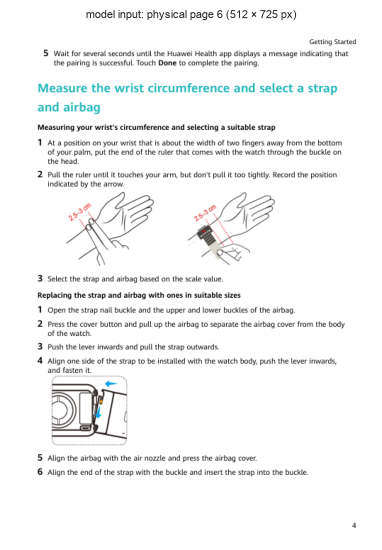

text condition, page 6 (native): getting started 5 wait for several seconds until the huawei health app displays a message indicating that the pairing is successful. touch done to complete the pairing. measure the wrist circumference and select a strap and airbag measuring your wrist's circumference and selecting a suitable strap 1 at a position on your wrist that is about the width of two fingers away from the bottom of your pal


**mmlb-0041** · `earlybird-110722143746-phpapp02_95.pdf` · format `Str` · sources ['Chart']

**Question:** On the chart showing average exit cap, there is one point that US, Europe, and China have the same average exit cap value. What is this value in USD million? Give me an integer

**Reference:** `300 million` · **evidence pages:** [26]

- **A. text, retrieved:** `350` (score 0.00) · cited [26] · supplied [7, 26, 6, 27, 33]

- **C. text, oracle:** `350` (score 0.00) · cited [26] · supplied [7, 26, 6, 27, 33]

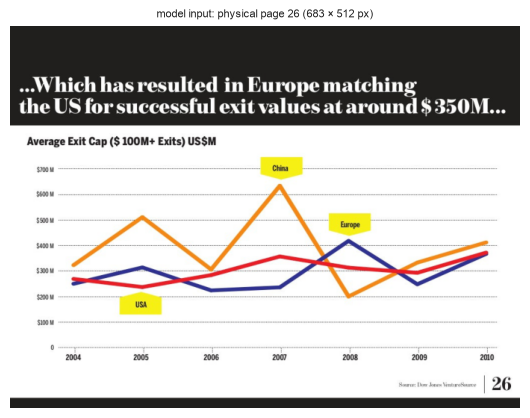

text condition, page 26 (OCR): ...which has resulted in europe matching the us for successful exit values at around $ 350m... average exit cap ($ 100m+ exits) ussm ct aa es ssomanna reenter nen tanteneenennnantnrnensenenanahensenenananentntaneianstaneneetntneneennanenennt source: dow jones venturesource | 26 eeee_—


In [36]:
def show_case(qid, conditions=None, max_pages=2):
    """Question, reference, every available prediction, then the evidence pages exactly as the image model sees them,
    with the start of the text the text model received for the same pages."""
    conditions = conditions if conditions is not None else categorized
    row = reference.loc[qid]
    lines = [
        f"**{qid}** · `{row['doc_id']}` · format `{row['answer_format']}` · sources {row['evidence_sources']}",
        f"**Question:** {row['question']}",
        f"**Reference:** `{row['answer']}` · **evidence pages:** {row['evidence_pages']}",
    ]
    for name, frame in conditions.items():
        match = frame[frame["qid"] == qid] if not frame.empty else frame
        if len(match):
            r = match.iloc[0]
            lines.append(f"- **{name}:** `{r['pred']}` (score {r['score']:.2f}) · cited {r['cited_pages']} · supplied {r['supplied_pages']}")
    display(Markdown("\n\n".join(lines)))
    pages_to_show = list(row["evidence_pages"])[:max_pages]
    fig, axes = plt.subplots(1, len(pages_to_show), figsize=(5.4 * len(pages_to_show), 5.6), squeeze=False)
    for ax, page_number in zip(axes[0], pages_to_show):
        png = render_page_png(row["doc_id"], page_number)
        ax.imshow(png_pixels(png))
        ax.set_title(f"model input: physical page {page_number} ({'{} × {}'.format(*png_size(png))} px)", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    for page_number in pages_to_show:
        source = "OCR" if page_lookup.loc[(row["doc_id"], page_number), "ocr_used"] else "native"
        print(f"text condition, page {page_number} ({source}): {normalize_text(page_lookup.loc[(row['doc_id'], page_number), 'text'])[:400]}")


# Inspection of two real text-baseline failures (frozen Notebook 14 predictions, no new call):
# a false abstention whose evidence page was supplied, and a wrong chart reading with the evidence cited.
for case in ("mmlb-0095", "mmlb-0041"):
    show_case(case)

### Interpretation (text conditions; measured on frozen data)

- **Where text A fails** (40 answerable): 7 correct, 7 retrieval failures (no evidence page supplied), 4 false abstentions and 22 wrong answers **with the evidence supplied**. Most errors therefore happen after retrieval, which is the space where images could help.
- **Not every text failure is a representation failure.** Of the 25 non-list answers wrong with the evidence supplied, the reference string is **absent** from the received text in 14 and **present** in 11, all chart/figure questions. For those 11, the text did carry the answer, and the model picked the wrong value. Short numbers can also match by coincidence, so "present" is an upper bound. Images are therefore not expected to fix every chart failure: some are reasoning or selection errors.
- **`mmlb-0095`**: a text-representation failure. The answer "2.5–3 cm" is a red label inside the drawing, absent from the native text layer, and the text model abstained in both A and C. Under the scorer, `2.5–3 cm` would get 0.75 (counted correct), so an image gain here is possible.
- **`mmlb-0041`**: a distractor in the text, plus a scoring trap. The slide title says "…exit values at around $350M", and the text model copied 350, citing the right page. The chart, legible at 683 × 512, shows the three lines meeting near $300M. But the question asks for "an integer", and the reference is the string `300 million` (format `Str`). Under the official rule, the answer `300` scores **0** and only "300 million" scores 1. A visual reader that reads the chart correctly and follows the instruction would still be scored wrong. Such cases go to the manual review as "annotation or scoring issue", not "visual reading".

In [37]:
MANUAL_REVIEW_CATEGORIES = ("retrieval", "text representation", "visual reading", "reasoning or aggregation", "citation", "abstention", "annotation or scoring issue")
# Filled ONLY after inspecting real image predictions with show_case: {qid: (category, one-sentence justification)}.
MANUAL_REVIEW = {
    # Pilot, reviewed 2026-11-20 by looking at the rendered evidence page and both replies.
    "mmlb-0355": ("reasoning or aggregation", "The 'Less' bar for Liberal (56 %) is legible in the 512 x 663 image, but both readers "
                  "answered with the chart's headline 'Democrats and those with more education…' instead of comparing the bars."),
    "mmlb-0731": ("visual reading", "The early Lufthansa logo (p.7) is a ~12-px yellow Twitter avatar in the 911 x 512 image; the model "
                  "reported only the later black-and-white logo (p.8) and merged the two time periods."),
    "mmlb-0736": ("annotation or scoring issue", "The slide says 'Within the first 4 hours: Airbus.com incorporates a pop-up notification'; "
                  "the reference 3 comes from the small screenshot caption 'Hour 3'. Both readers answered 4, which the slide text supports."),
    # Full run, reviewed 2026-11-20 from the rendered pages, the OCR text and both replies.
    "mmlb-0729": ("text representation", "The table on p.16 reads Germanwings 24, Lufthansa 12, Airbus 5 (legible in the image); OCR read "
                  "Lufthansa '42', so the text model summed 71. The image model summed 41 correctly."),
    "mmlb-0033": ("visual reading", "Image answer 64 instead of 63 = $236M − $173M: the two values sit in a small highlighted table "
                  "at 683 x 512 px; the OCR text carried both numbers and the text model was right."),
    "mmlb-0034": ("annotation or scoring issue", "Image answer 'Europe IPO index value was greater.' is right in substance but scores 0 "
                  "under the Str rule because it is a sentence, not the short answer 'Europe IPO'; the text model abstained."),
    "mmlb-0095": ("visual reading", "The image model read only '2.5' from the red label '2.5–3 cm' in the drawing (≈ 62 dpi); "
                  "the text model abstained because the label is not in the text layer."),
    "mmlb-0041": ("reasoning or aggregation", "Both readers answered 350, the value in the slide title, although the chart (legible) "
                  "shows the lines meeting near 300; even '300' would score 0 against the reference '300 million' (scoring trap)."),
    "mmlb-0096": ("visual reading", "Text answered 2 correctly from pp.9–10; the image model answered 1 and cited p.24, a page about "
                  "workout detection, in both B and D, so it did not locate the steps in the page images."),
    "mmlb-0313": ("visual reading", "Scanned guidebook (OCR proxy 0.06 at model resolution): the image model answered 1, the text model 2 "
                  "from OCR at 150 dpi. The question cites printed page 10 = physical page 11."),
}
assert all(category in MANUAL_REVIEW_CATEGORIES for category, _ in MANUAL_REVIEW.values())

if "1. retrieved pages: text → images (answerable)" not in PAIRED:
    print("Manual review pending: there are no image predictions yet. After the full run, inspect the review queue below "
          "with show_case(qid) and record a category for each case in MANUAL_REVIEW.")
else:
    primary = PAIRED["1. retrieved pages: text → images (answerable)"]
    queue = primary[primary["diagnostic"].str.contains("candidate|manual review|answer string was in the text")]
    queue = queue.assign(manual_label=queue["qid"].map(lambda qid: MANUAL_REVIEW.get(qid, ("pending", ""))[0]))
    print(f"Review queue: {len(queue)} questions ({int((queue['manual_label'] != 'pending').sum())} labelled).")
    display(queue[["qid", "evidence_group", "answer", "pred_a", "pred_b", "diagnostic", "manual_label"]])
    # Representative examples, chosen by rule: the first fixed, first broken and first persistent failure.
    for label in ("fixed", "broken", "both wrong"):
        candidates = primary[(primary["transition"] == label) & primary["evidence_supplied_a"].astype(bool)]
        if len(candidates):
            show_case(candidates["qid"].iloc[0])

Manual review pending: there are no image predictions yet. After the full run, inspect the review queue below with show_case(qid) and record a category for each case in MANUAL_REVIEW.


### Remaining manual review: pending questions only

The queue above mixes reviewed and unreviewed cases. Filtering on `manual_label == "pending"` leaves only the questions that still need a look at the page and both replies. The queue exists only when condition B ran (or was served from the response cache) in `full` mode; in `off` mode the cells below say so instead of failing.

In [38]:
REVIEW_QUEUE_READY = "1. retrieved pages: text → images (answerable)" in PAIRED

if not REVIEW_QUEUE_READY:
    print("No review queue in this execution: condition B has no predictions (vision mode 'off' or B incomplete). "
          "Re-run with VISUALDOC_VISION_MODE=full; B and D are then served from the response cache.")
else:
    pending = queue[queue["manual_label"] == "pending"]
    print(f"{len(pending)} of {len(queue)} queued questions still need a manual label.")
    display(pending[["qid", "evidence_group", "answer", "pred_a", "pred_b", "diagnostic"]])

No review queue in this execution: condition B has no predictions (vision mode 'off' or B incomplete). Re-run with VISUALDOC_VISION_MODE=full; B and D are then served from the response cache.


In [39]:
# Inspect the next unlabelled question; after labelling it in MANUAL_REVIEW and re-running, the next one appears here.
if REVIEW_QUEUE_READY and len(pending):
    show_case(pending["qid"].iloc[0])
elif REVIEW_QUEUE_READY:
    print("Every queued question has a manual label.")

## Step 15 — Save settings, manifests, predictions and results

Each execution gets its own folder under `experiments/runs/mmlongbench_doc_multimodal/`, separate from Notebook 14's folder so no earlier result can be overwritten. The folder is git-ignored. Its name is a UTC timestamp plus a hash of the configuration. An `off` execution also saves its folder: the render manifest and the cost estimates are results in their own right.

| file | content |
|---|---|
| `settings.json` | every setting, both prompts' hashes, image prompt, render box, measured tile rule, pacing budget, rate-limit headers, PDF SHA-256, populations, statuses, versions |
| `render_manifest.csv` | per page: size in px, zoom, effective dpi, PNG size, SHA-256 |
| `request_estimates.csv` | per request and tile rule: text/image/prompt tokens, context fit, cost bound |
| `smoke_test.json`, `errors.jsonl` | smoke record; every failed attempt and unparseable reply (sanitised) |
| `predictions_{retrieved,oracle}_images.jsonl` | one record per question, with image hashes and **no Base64** |
| `scored_*.csv`, `paired_*.csv`, `summary.json` | scored conditions, paired tables, metrics and paired summaries |

In [40]:
def to_jsonable(value):
    return value.item() if hasattr(value, "item") else str(value)


def write_jsonl(path, records):
    with open(path, "w") as handle:
        for record in records:
            handle.write(json.dumps(record, default=to_jsonable) + "\n")


configuration = {**SETTINGS, "image_system_prompt": IMAGE_SYSTEM_PROMPT, "render_label": RENDER_LABEL, "text_prompt_hash": baseline_settings["prompt_hash"]}
configuration_hash = hashlib.sha256(json.dumps(configuration, sort_keys=True, default=to_jsonable).encode()).hexdigest()[:8]
run_id = f"{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}_{configuration_hash}"
run_dir = RUNS_DIR / run_id
run_dir.mkdir(parents=True, exist_ok=True)

settings_record = {
    **configuration,
    "run_id": run_id,
    "configuration_hash": configuration_hash,
    "image_prompt_hash": IMAGE_PROMPT_HASH,
    "measured_tile_rule": MEASURED_TILE_RULE,
    "pacing_tokens_per_minute": PACING_TPM,
    "rate_limit_headers": RATE_LIMIT_HEADERS,
    "pdf_sha256": pdf_sha256,
    "subset_qids": subset["qid"].tolist(),
    "population_qids": {"B": retrieved_population["qid"].tolist(), "D": oracle_population["qid"].tolist()},
    "status": {"smoke": smoke_record["status"], "B": RETRIEVED_STATUS, "D": ORACLE_STATUS},
    "environment": {"python": sys.version.split()[0], "pymupdf": pymupdf.VersionBind, "pandas": pd.__version__, "numpy": np.__version__,
                    "openai": getattr(openai, "__version__", None), "tiktoken": getattr(tiktoken, "__version__", None), "os": platform.system()},
}
(run_dir / "settings.json").write_text(json.dumps(settings_record, indent=2, default=to_jsonable))
manifest.to_csv(run_dir / "render_manifest.csv", index=False)
estimates.to_csv(run_dir / "request_estimates.csv", index=False)
(run_dir / "smoke_test.json").write_text(json.dumps(smoke_record, indent=2, default=to_jsonable))
write_jsonl(run_dir / "predictions_retrieved_images.jsonl", retrieved_records)
write_jsonl(run_dir / "predictions_oracle_images.jsonl", oracle_records)

error_rows = [{"qid": "smoke_test", "stage": "api_call", **failure} for failure in smoke_record.get("failed_attempts", [])]
for condition, records in (("B", retrieved_records), ("D", oracle_records)):
    for record in records:
        error_rows += [{"condition": condition, "qid": record["qid"], "stage": "api_call", **failure} for failure in record.get("failed_attempts", [])]
        if record["status"] == "parse_error":
            error_rows.append({"condition": condition, "qid": record["qid"], "stage": "parse", "message": record["parse_error"], "raw": (record["raw_response"] or "")[:500]})
write_jsonl(run_dir / "errors.jsonl", error_rows)

for name, frame in CONDITIONS.items():
    if not frame.empty:
        file_name = "scored_" + re.sub(r"[^a-z]+", "_", name.lower()).strip("_") + ".csv"
        frame.drop(columns=["raw_response", "failed_attempts"], errors="ignore").to_csv(run_dir / file_name, index=False)
for name, paired in PAIRED.items():
    paired.to_csv(run_dir / ("paired_" + re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")[:60] + ".csv"), index=False)

summary = {
    "run_id": run_id,
    "mode": GENERATION_MODE,
    "status": settings_record["status"],
    "metrics": {name: condition_metrics(frame) for name, frame in CONDITIONS.items()},
    "paired": {name: paired_summary(paired) for name, paired in PAIRED.items()},
    "usage": {"B": usage_summary(retrieved_records), "D": usage_summary(oracle_records)},
    "manual_review": MANUAL_REVIEW,
}
(run_dir / "summary.json").write_text(json.dumps(summary, indent=2, default=to_jsonable))

pd.DataFrame([{"file": path.name, "bytes": path.stat().st_size} for path in sorted(run_dir.iterdir())]).assign(folder=str(run_dir.relative_to(PROJECT_ROOT)))

,file,bytes,folder
0,errors.jsonl,0,experiments/runs/mmlongbench_doc_multimodal/20261120T135912Z_3e6c4902
1,paired_0_reference_text_retrieved_oracle.csv,11329,experiments/runs/mmlongbench_doc_multimodal/20261120T135912Z_3e6c4902
2,predictions_oracle_images.jsonl,0,experiments/runs/mmlongbench_doc_multimodal/20261120T135912Z_3e6c4902
3,predictions_retrieved_images.jsonl,0,experiments/runs/mmlongbench_doc_multimodal/20261120T135912Z_3e6c4902
4,render_manifest.csv,17672,experiments/runs/mmlongbench_doc_multimodal/20261120T135912Z_3e6c4902
5,request_estimates.csv,17079,experiments/runs/mmlongbench_doc_multimodal/20261120T135912Z_3e6c4902
6,scored_a_text_retrieved.csv,24829,experiments/runs/mmlongbench_doc_multimodal/20261120T135912Z_3e6c4902
7,scored_c_text_oracle.csv,18557,experiments/runs/mmlongbench_doc_multimodal/20261120T135912Z_3e6c4902
8,settings.json,6375,experiments/runs/mmlongbench_doc_multimodal/20261120T135912Z_3e6c4902
9,smoke_test.json,25,experiments/runs/mmlongbench_doc_multimodal/20261120T135912Z_3e6c4902


## Validation checks

Assertions for the properties every result depends on. If a later change breaks one, the notebook stops here instead of reporting a misleading number. They map to the task's validation list: page numbering (1–2), identical page lists (3–4), offline request tests (5, Steps 7 and 9), smoke and pilot gating (6–7, Step 10), denominators (8) and saving, cost logging and secrets (9).

In [41]:
# 1–2. Page numbering: the synthetic known-answer test and the real-page mapping test passed (Step 6),
#      and every cached image is byte-identical to a fresh render of its (document, page).
assert all(row["correct"] for row in synthetic_rows) and (mapped["150 dpi vs native p"] > neighbours).all()
for row in manifest.itertuples():
    assert hashlib.sha256(cache_path(row.doc_id, row.page).read_bytes()).hexdigest() == row.sha256

# 3. Retrieved images use exactly the retrieved-text pages, in the same order.
assert all(row.pages == retrieved_pages_saved[row.qid] for row in retrieved_population.itertuples())
assert all(r["supplied_pages"] == retrieved_pages_saved[r["qid"]] for r in retrieved_records)

# 4. Oracle images use exactly the oracle-text pages, in the same order.
assert all(row.pages == oracle_pages_saved[row.qid] for row in oracle_population.itertuples())
assert all(r["supplied_pages"] == oracle_pages_saved[r["qid"]] for r in oracle_records)

# 5. Model control: every image reply (if any) came from the baseline's snapshot.
served_image_models = {r["served_model"] for r in retrieved_records + oracle_records if r.get("served_model")}
assert served_image_models <= {SETTINGS["model_name"]}, served_image_models

# 6. Protocol skips are decided by the estimate alone (never by an outcome), and only for requests that do not fit.
for record in retrieved_records + oracle_records:
    if record["status"] == "skipped_context_limit":
        assert record["estimated_prompt_tokens"] + SETTINGS["max_output_tokens"] > SETTINGS["context_window_tokens"]

# 7. Denominators: a scored image condition covers exactly its population minus protocol skips, and contains no failed call.
for frame, records, population_frame in ((image_B, retrieved_records, retrieved_population), (image_D, oracle_records, oracle_population)):
    if not frame.empty:
        skipped = {r["qid"] for r in records if r["status"] in SKIPPED_BY_PROTOCOL}
        assert set(frame["qid"]) == set(population_frame["qid"]) - skipped
        assert frame["status"].isin(["ok", "parse_error"]).all()
assert image_B.empty or set(image_B["qid"]) == set(retrieved_population["qid"])  # B allows no skip (gate condition)

# 8. Paired comparisons are paired: identical question sets on both sides, one row per question.
for name, (a, b) in COMPARISONS.items():
    assert set(PAIRED[name]["qid"]) == set(a["qid"]) == set(b["qid"]) and PAIRED[name]["qid"].is_unique, name

# 9. Saved files: no API key, no Base64 image payload.
for path in run_dir.iterdir():
    content = path.read_text()
    assert not SECRET_PATTERN.search(content), f"key-like string in {path.name}"
    assert "base64," not in content and not re.search(r"[A-Za-z0-9+/]{2000,}", content), f"image payload in {path.name}"

print("All validation checks passed.")

All validation checks passed.


## Results and interpretation

**Full run** `20261119T232847Z_65ccf1ef` (2026-11-20, `full` mode, `gpt-4o-mini-2024-07-18`, 512-px page images):

- **Infrastructure.** 57/57 replies for B and 38/38 for D, all `ok` on the first attempt, with 0 errors and 0 unparseable replies. `mmlb-0035` and `mmlb-0039` were skipped in D by protocol (≈ 184k and 142k tokens).
- **Cost model.** Prompt tokens matched the estimate within 1 token on every request.
- **Spend.** Live cost at list prices: $0.555 (B) + $0.139 (D). 25 D replies came from the cache. In 24 of them the D request was byte-identical to the B request, because all evidence was already in the top 5. The 25th, `mmlb-0036`, was the pilot's own D request. Total project spend for the image conditions, including the smoke and pilot runs, is ≈ $0.77.
- **Token cost of images.** Image input used ≈ 37× the prompt tokens of text: 4.05M versus 108k for the 57 retrieved questions.

### Four conditions (same questions, same pages, same model)

| metric | A text, retrieved | B images, retrieved | C text, oracle* | D images, oracle* |
|---|---|---|---|---|
| accuracy on answerable | 0.175 (7/40) | 0.175 (7/40) | 0.237 (9/38) | 0.289 (11/38) |
| accuracy, all 57 / F1 | 0.263 / 0.165 | 0.228 / 0.156 | — | — |
| correct abstention (17 unanswerable) | 0.471 | 0.353 | — | — |
| false abstention (answerable) | 0.100 | 0.025 | 0.079 | 0.026 |
| citation validity | 1.000 | 0.895 | 1.000 | 0.921 |
| cites an evidence page | 0.650 | 0.600 | 0.895 | 0.789 |

\* 38 questions: D's two context-limit skips are removed from C too.

### Paired comparisons (question by question)

| comparison | n | accuracy | fixed | broken | McNemar p | documents better / worse / equal |
|---|---|---|---|---|---|---|
| 1. retrieved: text → images | 40 | 0.175 → 0.175 | 3 | 3 | 1.00 | 1 / 3 / 2 |
| 1b. same, all questions | 57 | 0.263 → 0.228 | 3 | 5 | 0.73 | 1 / 4 / 1 |
| 2. oracle: text → images | 38 | 0.237 → 0.289 | 6 | 4 | 0.75 | 2 / 3 / 1 |
| 3. images: retrieved → oracle | 38 | 0.184 → 0.289 | 4 | 0 | 0.13 | 2 / 0 / 4 |
| *reference: text, retrieved → oracle* | 40 | 0.175 → 0.225 | 2 | 0 | 0.50 | 2 / 0 / 4 |

### What the predictions show

1. **Images do not raise accuracy on the retrieved pages: they trade errors.** The 3 fixes and 3 breaks follow the representation, not chance:
   - **All fixes are in image-only slide decks** where the 512-px image is legible and the OCR text was wrong or missing. In `mmlb-0729`, OCR read Lufthansa's "12" tweets as "42", so the text model summed 71. The image table gives 41, the reference. `mmlb-0727` (12) is fixed the same way in D. In `mmlb-0037`, the magazine names are logos that OCR cannot read, and D answers `['The Economist', 'TIME']` exactly.
   - **The breaks lose small detail.** `mmlb-0033`: 64 instead of 63, read from a small table. `mmlb-0313`: the scanned guidebook, where the OCR proxy is 0.06 at model resolution while the text condition had OCR at 150 dpi. `mmlb-0096`: the image model cited an irrelevant page.
2. **Images make the model answer more often, in both directions.** False abstentions fall from 4 to 1 (answerable), but correct abstentions also fall from 8/17 to 6/17. `mmlb-0038` and `mmlb-0770` now get invented answers taken from a related page. Over all 57 questions, accuracy drops from 0.263 to 0.228 and F1 from 0.165 to 0.156.
3. **A new citation failure: printed page numbers.** 9 image citations name a page that was not supplied, against 0 for text. In 8 of the 9, the cited number is physical − 1. That is exactly the page number printed on the page in the PG report and in `bdf54dxa` (checked on 9 pages). The image reader sometimes cites the number it sees on the page instead of the `[Page N]` tag. The "cites an evidence page" rate for images is therefore underestimated, and the prompt or the page tags need to address it (Next step).
4. **Some near misses are scoring artefacts.** `mmlb-0034`: the image answer "Europe IPO index value was greater." is right in substance but scores 0 because it is a sentence. `mmlb-0041`: both readers copied the title value 350, and the reference string "300 million" would also reject an integer answer of 300. The official GPT-4o answer-extraction stage, not used here, would score some of these differently.
5. **Retrieval matters more for the image reader.** Supplying the oracle pages fixes 4 image answers and breaks none (0.184 → 0.289 on 38 questions), against 2 fixed for text (0.184 → 0.237 on the same 38). All 4 image fixes (`mmlb-0036`, `-0037`, `-0727`, `-0740`) are questions with **no** evidence page in the BM25 top 5. Once the image reader receives the page, it reads it. On the same pages, text fixed only `mmlb-0740` and `mmlb-0359`, because its errors are mostly reading errors (Notebook 14).

### Hypotheses

- **H1** (images > text on retrieved pages): **not supported** on this subset. 0.175 versus 0.175, 3 fixed and 3 broken, and 1 of 6 documents improves. Over all 57 questions, images score lower because they abstain less.
- **H2** (larger gain on chart/figure questions): **not supported.** The gain is 0.000 for both groups on the retrieved pages. On the oracle pages, chart/figure +0.033 (30 questions) versus text-only +0.125 (8 questions). The pattern is better described by **document**: every fix is in the two image-only slide decks (`germanwings` +0.27 / +0.36, `earlybird` +0.20 in D). The 3 breaks on the retrieved pages involve small detail (a small table, a 60-dpi scan, a manual page where the model cited an irrelevant page). With 6 documents this is a hypothesis for the next experiment, not a finding.
- **H3** (images > text on oracle pages): **direction consistent, not established.** 0.237 → 0.289 (+2 questions net: 6 fixed, 4 broken, McNemar p = 0.75), and only 2 of 6 documents improve. One more broken question would erase it.

### Error taxonomy, retrieved pages (40 answerable, from the diagnostic table and the manual review)

- **Retrieval failure:** 8 questions have no evidence page in the top 5, so neither representation can answer from evidence.
- **Text-representation failures fixed by images:** 1 clear case (`mmlb-0729`, OCR digit error). In 2 more fixes (`mmlb-0732`, `-0739`) the answer string was already in the text.
- **Visual-reading failures:** 2 candidates where text was right and images wrong (`mmlb-0033`, `mmlb-0096`), plus `mmlb-0313` among the retrieval cases.
- **Wrong under both representations with the evidence supplied:** 23 questions, mostly counting across slides, multi-step arithmetic on chart values, and headline-versus-data confusions (`mmlb-0041`, `mmlb-0355`).
- **Annotation or scoring:** at least 3 cases (`mmlb-0034`, `-0041`, `-0736`).
- **Manual review:** 9 of the 28 queued questions are labelled in `MANUAL_REVIEW`, plus `mmlb-0313`, which sits in the retrieval-failure group. The other 19 remain to be reviewed.

### Synthesis

On this subset, with gpt-4o-mini and the 60-dpi images its token cost allows, **swapping extracted text for page images does not improve accuracy on the retrieved pages**. Images change *which* questions are answered: they recover numbers and logos that OCR destroyed on slide decks, and they lose small digits and scanned text that OCR at 150 dpi or native text kept. They also make the model abstain less and cite printed page numbers. The most promising signal is that the image reader benefits more from correct pages than the text reader. All of this rests on 38–57 questions in 6 documents, from one run per condition, so every statement here is a hypothesis to test, not a result to generalise.

In [42]:
def hypothesis_status(paired_name, statement, select=None):
    """Observed direction only. 'Consistent' is not 'confirmed': 40 clustered questions cannot confirm a hypothesis."""
    if paired_name not in PAIRED:
        return {"hypothesis": statement, "evidence": "—", "status": "not tested: no image results in this execution"}
    paired = PAIRED[paired_name]
    if select is not None:
        gains = {group: frame["score_diff"].mean() for group, frame in paired.groupby("evidence_group")}
        chart_gain, text_gain = gains.get("chart or figure", np.nan), gains.get("text, layout or table only", np.nan)
        evidence = f"gain chart/figure {chart_gain:+.3f} vs text-only {text_gain:+.3f} (n = {paired['evidence_group'].value_counts().to_dict()})"
        difference = chart_gain - text_gain  # NaN when a group is absent from this population
    else:
        s = paired_summary(paired)
        evidence = (f"{s['accuracy A']:.3f} → {s['accuracy B']:.3f}; fixed {s['fixed (A wrong → B right)']}, broken {s['broken (A right → B wrong)']}; "
                    f"McNemar p {s['exact McNemar p (ignores clustering)']:.3f}; documents better/worse/equal {s['documents better / worse / equal']}")
        difference = s["difference B − A"]
    if np.isnan(difference):
        status = "not testable: a comparison group is empty in this population"
    elif difference > 0:
        status = "direction consistent (exploratory)"
    elif difference < 0:
        status = "direction NOT consistent"
    else:
        status = "no difference observed"
    return {"hypothesis": statement, "evidence": evidence, "status": status}


hypotheses = pd.DataFrame(
    [
        hypothesis_status("1. retrieved pages: text → images (answerable)", "H1: images > text on the same retrieved pages"),
        hypothesis_status("1. retrieved pages: text → images (answerable)", "H2: image gain larger on chart/figure than on text-only questions", select="evidence_group"),
        hypothesis_status("2. oracle pages: text → images", "H3: images > text on the oracle pages"),
    ]
)
with pd.option_context("display.max_colwidth", 140):
    display(hypotheses)

,hypothesis,evidence,status
0,H1: images > text on the same retrieved pages,—,not tested: no image results in this execution
1,H2: image gain larger on chart/figure than on text-only questions,—,not tested: no image results in this execution
2,H3: images > text on the oracle pages,—,not tested: no image results in this execution


## Limitations

- **Small, clustered sample.** 40 answerable questions in 6 documents (17 unanswerable). One question moves accuracy by 0.025. McNemar treats questions as independent, but they are clustered in documents, so read its p-values as optimistic and use the document-level counts. Every subgroup result (evidence type, document, retrieval group) is exploratory.
- **Resolution is set by cost, not by fidelity.** gpt-4o-mini charges ~5,667 tokens per 512-px tile, so 5 pages fit the context only at about 60 dpi (2 tiles per page). On the academic paper and the scanned guidebook, OCR recovers ≤ 6 % of words from these images (Step 6). The comparison is "text versus 512-px page images", not "text versus what a human sees".
- **H2 is confounded.** Chart and figure questions sit mostly in the legible slide decks, while text questions sit partly in the illegible documents. The evidence-type difference cannot be separated from document and legibility with 6 documents.
- **The tile rule is unverified until the smoke test.** If the API upscales small images, the design does not fit gpt-4o-mini's context at all, and a decision is needed (Step 8).
- **Prompt wording differs** in 5 of 10 system-prompt lines (evidence description only). **Text was truncated** at 3,500 characters per page in A/C; images are not truncated.
- **Oracle skips.** Two counting questions (10 and 13 evidence pages) exceed the context as images and leave condition D by protocol. Comparison 2 is on the remaining questions, and the text side is restricted to them. Both were wrong in text.
- **Local scoring.** The rule-based stage of the official scorer is re-implemented. The official GPT-4o answer-extraction stage is replaced by structured output. Scores are local diagnostics, not leaderboard numbers.
- **Run-to-run variation** at temperature 0: 3–6 of 57 text predictions changed between identical runs in Notebook 14. One image run cannot rule out a one-question swing, and the response cache, by design, does not re-sample.
- **The OCR legibility proxy** uses Tesseract, which reads small text worse than a VLM may, so it bounds what text the image contains rather than what GPT-4o-mini perceives.
- **Prices** are assumed list prices. Cost figures are upper bounds (completion at its cap, cached-input discounts ignored).

## Failure case to remember

The first version of the Step 6 mapping check OCR-ed the **model-resolution** image and asserted that it matched its own page's native text best. It failed on the academic paper. OCR recovered 0 % of the words of pages 15 and 22 at ≈ 60 dpi, so page `p` tied with `p ± 1` at zero. The failure was not a page-mapping bug. It was the first measurement of how much text the affordable resolution destroys. The check now verifies the mapping at 150 dpi and reports legibility separately.

## Next step

Done on 2026-11-20: the smoke test (tile rule measured: no upscaling), the pilot (9 requests), and the full run (57 + 38 requests, ≈ $0.69 live).

1. **Fix the citation failure before any new image run.** State in the image prompt that page numbers printed on the page are not the `[Page N]` tags, or stamp the tag into the image. This is a prompt change, so it is a new condition and must be compared with B, not substituted for it.
2. **Finish the manual review** of the remaining 19 queued questions with `show_case(qid)`.
3. **Separate representation from resolution.** Repeat A–D with a model whose image tokens allow the default 768-px input, re-running the text conditions with the same model. Alternatively, test text + image together on gpt-4o-mini.
4. **Measure run-to-run variation for images.** Re-run B once with `reuse_cached_responses = False` (≈ $0.56). A 3-fixed / 3-broken result needs a noise reference.
5. **Enlarge the sample** (more documents or seeds) before treating any subgroup pattern, such as slide decks versus scans, as a finding.